In [272]:
import pandas as pd
import numpy as np
from pathlib import Path
from typing import Dict, List, Union, Optional, Mapping, Sequence
import matplotlib.pyplot as plt
from matplotlib.text import Text
from matplotlib.ticker import AutoMinorLocator, MaxNLocator
from IPython.display import display
from scipy import stats
import seaborn as sns
import os
import datetime
import subprocess
from mech_dot_inp_gen import *
import jinja2
import copy
from Visualization_scripts import *

In [273]:
class OptimaOutput:
    def __init__(self, job_name: Union[str, Path],
                 optima_path: Optional[Union[str, Path]] = None):

        self.job_name = str(job_name)
        if optima_path == None:
            self.optima_path = Path("/home/szupernikusz/OptimaPP/outputs")
        self.job_folder = self.optima_path / job_name
        file_path = self.job_folder / "mechanismInfo.txt"
        try:
            with open(file_path, "r") as f:
                self.mech_info = f.read()
        except Exception as e:
            raise e

In [274]:
class OptimaMechtest(OptimaOutput):
    def __init__(self, job_name: Union[str, Path],
                 input_mech: str,
                 optima_path: Optional[Union[str, Path]] = None,
                 errf_type: Union[str, List[str]] = "default"):
        super().__init__(job_name, optima_path)

        self._errf_files = {
           "default": "errfValues",
           "data_series": "errfValues_by_data_series", 
           "points": "errfValues_by_points",
           "species": "errfValues_by_species"
            }

        if (self.job_folder / "debug").exists():
            self.all_data = {}
            for csv_data in (self.job_folder / "debug").glob("*.csv"):
                try:
                    self.all_data[csv_data.stem] = pd.read_csv(csv_data)
                except Exception as e:
                    print(e)
        print((self.job_folder / f"mechTestResults_{input_mech}.csv"))
        if (self.job_folder / f"mechTestResults_{input_mech}.csv").exists():
            print((self.job_folder / f"mechTestResults_{input_mech}.csv").exists())
            self.all_sheets_dP = pd.read_csv(self.job_folder / f"mechTestResults_{input_mech}.csv",  # dP as in the info in dataPoints
                                        header=None,
                                        delimiter=';',
                                        index_col=False,
                                        names=['xml', 'time_point', 'species', 'dP_val', 'sim_val'],
                                        )#low_memory=False)
            #print(self.all_sheets_dP)
            self.get_coarse_df(all_sheets_dP=self.all_sheets_dP)

        stac_eq_df = pd.concat({k: v.iloc[-1] for k, v in self.all_data.items()}, axis=1)                # makes a dict() with the
        #followed18 = pd.concat({k: v.iloc[-1] for k, v in self.orig_time_sim_df.items()}, axis=1)        # same keys, the values are
        self.df_basal = stac_eq_df.iloc[3:-1].T                                                          # the last elements i.e.,
        #self.df_followed18 = followed18.T                                                                # t = last time_point

    def __str__(self):
        if not self.df_basal.empty and not self.df_followed18.empty:
            return f"Mech object was successfully generated with fields\ndf_basal: {self.df_basal.shape}\ndf_followed18: {self.df_followed18.shape}"
        elif self.df_basal.empty and not self.df_followed18.empty:
            return "Unsuccessful, error with df_basal"
        elif not self.df_basal.empty and self.df_followed18.empty:
            return "Unsuccessful, error with df_followed18"
        else:
            return "Mech object was not successfully created"

    def get_coarse_df(self, all_sheets_dP):
        self.orig_time_sim_df = {}
        self.orig_time_exp_df = {}

        time_point = 0
        species = 'ilyen_species_tuti_nem_lesz'
        self.failed_sims_xmls = []

        for _, row in all_sheets_dP.iterrows():
            if row.xml in self.failed_sims_xmls:
                continue

            xml_name = row.xml
            sim_val = row.sim_val
            exp_val = row.dP_val

            if row.species == species:
                time_point += 1
            else:
                species = row.species
                time_point = 1

            if sim_val != 'FAILED':
                # ensure dict entries exist
                if xml_name not in self.orig_time_sim_df:
                    self.orig_time_sim_df[xml_name] = pd.DataFrame()
                if xml_name not in self.orig_time_exp_df:
                    self.orig_time_exp_df[xml_name] = pd.DataFrame()

                # ALWAYS assign (no else:)
                self.orig_time_sim_df[xml_name].loc[time_point, species] = float(sim_val)
                self.orig_time_exp_df[xml_name].loc[time_point, species] = exp_val
            else:
                self.failed_sims_xmls.append(xml_name)

        # make sure rows are in time order and numeric
        for xml, df in self.orig_time_sim_df.items():
            self.orig_time_sim_df[xml] = df.sort_index().apply(pd.to_numeric, errors='coerce')

        # build “followed18” as last valid values per species
        followed18 = pd.concat(
            {xml: df.ffill().iloc[-1]              # or: df.apply(lambda c: c.dropna().iloc[-1])
            for xml, df in self.orig_time_sim_df.items()},
            axis=1
        )
        self.df_followed18 = followed18.T

In [275]:
class Processing:
    def __init__(self, species_txt: str, ) -> None:
        self.species = self.get_species(species_txt)
        self.observables, self.not_observables = self.get_observables()

    def get_species(self, species_txt: str) -> list[str]:
        species = []
        with open(species_txt, 'r') as f:
            lines = f.readlines()
        for line in lines:
            for s in line.strip().split():
                species.append(s)
        print(len(species), species)
        return species

    def get_observables(self) -> tuple[list[str], list[str]]:
        dont_observe = []
        for s in self.species:
            if s == 'Q' or 'LKB1' in s or 'PP2A' in s or 'GLUT1' in s or 'RAP' in s or 'RK' in s or s in ['RHEB', 'PYRUVATE', 'AKT', 'TSCA']:
                dont_observe.append(s)
            elif s == 'FKBP12' or s == 'REF':
                dont_observe.append(s)
        observe = list(set(self.species) - set(dont_observe))
        print(len(observe), observe)
        return observe, dont_observe

In [276]:
class Model:
    def __init__(self, model_name: str, ics_df_path, # data_source: a pandas DataFrame
                 dont_observe: list[str], time_points: list[float],
                 time_course_vals: Union[dict[str, list[float]], float],
                 food: str, must_be_zero: list[str]=[], uncertainty=False,
                 inputs: dict[str, float]={'GLUCOUT': 6e-6}): # dict[stress_species: init_cc] = [rap extracell.: [mol/cm^3]]
        self.model_name = model_name
        self.ics_df = pd.read_csv(ics_df_path, sep=',')
        self.ics_df['minconc'] = self.ics_df['minconc'].astype(float)
        self.ics_df['maxconc'] = self.ics_df['maxconc'].astype(float)
        self.ics_df['value'] = self.ics_df['value'].astype(float)
        self.ics_df.species = [s.upper() for s in self.ics_df.species]
        self.species = self.ics_df['species'].to_list()
        self.output_species = list(set(self.species) - set(dont_observe))
        self.time_points = time_points
        if isinstance(time_course_vals, float):
            self.time_course_vals = self.gen_time_course_vals(time_course_vals)
        else:
            self.time_course_vals = time_course_vals
        self.food = food
        self.must_be_zero = must_be_zero
        self.uncertainty = uncertainty
        self.inputs = inputs

        self.ranges = self.get_bounds()
        print(f"range values stored in model.ranges of length {len(self.ranges.keys())}")
        self.get_sigmas()
        self.gen_exp_data()

    def get_bounds(self) -> dict[str, tuple[float, float]]:
        bounds = dict()
        for _, row in self.ics_df.iterrows():
            if 'REF' not in row.species and row.species not in self.must_be_zero:
                if row.value < 1e-13:
                    lb = 1e-14
                    ub = 1e-13
                elif row.minconc == row.maxconc:
                    lb = row.minconc
                    ub = row.maxconc
                else:
                    if row.value/2 >= row.minconc:
                        lb = (row.value/2)
                    else:
                        lb = row.minconc
                    if row.value*1.5 <= row.maxconc:
                        ub = (row.value*1.5)
                    else:
                        ub = row.maxconc
            bounds[row.species.upper()] = [lb, ub]
        return bounds

    def get_sigmas(self):
        self.sigmas = dict()
        for key, value in self.ranges.items():
            if self.uncertainty:
                if key in self.must_be_zero: # this line might be unnecessary, as I think we need sigma only if the species is an output
                    self.sigmas[key] = 5e-18
                elif key in self.output_species:
                    if value[1] > value[0]:
                        self.sigmas[key] = ((value[1]-value[0])/8)
                    else:
                        self.sigmas[key] = 5e-13
            else:
                self.sigmas[key] = 2.5e-11

    def gen_time_course_vals(self, time_course_vals):
        species_time_course = {}
        for s in self.species:
            species_time_course[s] = np.ones(len(self.time_points)) * time_course_vals
        return species_time_course

    def gen_exp_data(self):
        self.exp_data = pd.DataFrame()
        self.exp_data['time'] = self.time_points
        for s in self.output_species:
            self.exp_data[s] = self.ics_df[self.ics_df['species'] == s].iloc[0, 2] # "exp_data" = value of the csv column

In [277]:
class Genesis:
    def __init__(self, model: Model, max_digit = 4):
        self.model = model
        self.maxdigit = max_digit

    def create_xml_files(self, output_xmls_path: str, num_of_xmls: int,
                         xml_template_path: str, prefix: str='', kiir=True) -> None:
        if not os.path.exists(output_xmls_path):
            os.makedirs(output_xmls_path)
        self.num_xmls = num_of_xmls
        self.output_dir = output_xmls_path
        env = jinja2.Environment(loader=jinja2.FileSystemLoader(os.path.dirname(xml_template_path)))
        self.template = env.get_template(os.path.basename(xml_template_path))

        if kiir:
            for i in range(1, num_of_xmls+1):
                np.random.seed(i+1)
                self.random_ics = self.get_random_ics()
                self.make_xml_output(i, output_xmls_path, prefix)

    def get_random_ics(self) -> dict[str, float]:
        random_ics = {}
        if self.model.uncertainty:
            for key in self.model.species:
                if key not in self.model.must_be_zero:
                    random_ics[key] = np.random.uniform(*self.model.ranges[key])
                else:
                    random_ics[key] = 0
        else:
           random_ics = dict(zip(self.model.ics_df['species'], self.model.ics_df['value']))
        for key in self.model.inputs.keys():
            random_ics[key] = self.model.inputs[key]
        random_ics["REF"] = 1.0
        if self.model.food == 'stac':
            random_ics['Q'] = 6e-6
        return random_ics

    def make_xml_output(self, file_index: int, output_xmls_path: str, prefix) -> None:
        dataPoints = [self.compileDataRow(row.values) for _, row in self.model.exp_data.iterrows()]
        output = self.template.render(ics=self.random_ics, relsigmas=self.model.sigmas,
                                      variables=self.model.output_species, dataPoints=dataPoints)
        padded_number = str(file_index).zfill(self.maxdigit)
        filename = f"{prefix}_{padded_number}.xml"
        with open(os.path.join(output_xmls_path, filename), 'w') as f:
            f.write(output)

    def compileDataRow(self, dataPoints):
        meas = "".join(f"<{v}>{{:.4e}}</{v}>" for v in self.model.exp_data.columns)
        return f"<dataPoint>{meas.format(*dataPoints)}</dataPoint>"

In [278]:
class Simulation:
    def __init__(self, gen: Genesis, xmls_in_one_opp: int) -> None:
      self.gen = gen
      self.get_xml_vec(xmls_in_one_opp)

    def get_xml_vec(self, xmls_in_one_opp) -> None:
      self.xmls = []
      for i in range(1, self.gen.num_xmls, xmls_in_one_opp):
          xml_cnt = np.arange(i, i+xmls_in_one_opp, 1) 
          self.xmls.append(xml_cnt)

    def opp_gen(self, opp_output_dir, opp_name_prefix, kiir, mech_file, food) -> None:
      self.opps = []
      self.indices = []
      self.food = food
      self.mech_file = mech_file
      self.mech_inp_name = self.mech_file.split('/')[-1].split('.inp')[0]
      for num in self.xmls:
          opp_filename = f"{opp_name_prefix}_{num[-1]}.opp"
          self.opps.append(opp_filename)
          self.indices.append(f"{num[-1]}")
          if kiir:
            opp_content = self.generate_opp_content(xml_folder=self.gen.output_dir,
                                                    num_xmls=num,
                                                    mech_file=mech_file,
                                                    name=self.food)
            with open(os.path.join(opp_output_dir, opp_filename), "w") as f:
              f.write(opp_content)

    def generate_opp_content(self, xml_folder: str, num_xmls: Union[list[int], list[list[int]]],
                             mech_file: str, name: str, time_limit: int = 50, thread_limit: int = 32,
                             settings_tag: str = "systems_biology", solver: str = "cantera") -> str:
      mech_name = mech_file.split('/')[-1].split('.inp')[0]
      yaml = mech_file.split('.inp')[0]

      # Create MECHMOD section
      mechmod = f"""MECHMOD
      USE_NAME         {mech_name}
      MECH_FILE        {mech_file}
      COMPILE_{solver} {yaml}.yaml
      END
      """

      # Create MECHTEST section
      mechtest = f"""MECHTEST
      MECHANISM  {mech_name}
      TIME_LIMIT {time_limit}
      THREAD_LIMIT {thread_limit}
      SETTINGS_TAG {settings_tag}
      FALLBACK_TO_DEFAULT_SETTINGS
      PLOTS FALSE

      SOLVER {solver}
      SAVE_STATES      CSV
      """

      # Add each XML file name
      for xml in num_xmls:
          padded_number = str(xml).zfill(self.gen.maxdigit)
          mechtest += f"      NAME {xml_folder}/{name}_{padded_number}.xml\n"

      mechtest += "END\n"

      return mechmod + "\n" + mechtest

    def sim_runner(self, log_location:str = '', date_prefix: str = ''):
      self.parent_path = os.path.join(Path.cwd().parents[4], "OptimaPP") #Path.cwd().parents[2]
      #print(f"self.parent_path: {self.parent_path}")

      if log_location == '':
        for idx, opp_file in enumerate(self.opps):
            command = ["bin/Release/OptimaPP", f"../Projects/Semmelweis_BCRN/BCRN/1_mechtest/{opp_file}"]
            print(f"Running: {' '.join(command)}")
            subprocess.run(command, check=True, cwd=self.parent_path)
      else:
        for idx, opp_file in enumerate(self.opps):
          command = ["bin/Release/OptimaPP", f"../Projects/Semmelweis_BCRN/BCRN/1_mechtest/{opp_file}"]
          print(f"Running: {' '.join(command)}")
          log_idx = self.xmls[idx][-1]
          with open(f"{log_location}/run_log_stac_starve_rap{log_idx}.txt", "w") as log:
              subprocess.run(command, check=True, stdout=log, stderr=subprocess.STDOUT, cwd=self.parent_path)

In [279]:
os.path.join(Path.cwd().parents[4], "OptimaPP")

'/home/szupernikusz/OptimaPP'

In [280]:
class Natural_Selection:
    def __init__(self, sim: Simulation) -> None:
        self.sim = sim
        self.sim_data: dict[str, OptimaMechtest] = {}
        self.get_sim_data()
        #self.survival_of_the_fittest()

    def get_sim_data(self) -> None:
        for idx, key in enumerate(self.sim.indices):
            self.sim_data[key] = OptimaMechtest(job_name=self.sim.opps[idx],
                                                input_mech=self.sim.mech_inp_name)

    def sigma_range(self, meas, sim, sigma):
        radius = (sim-meas)/sigma
        return radius
    
    def isit_init(self, row):
        lut = self.sim.gen.model.ics_df
        rel_sigmas = self.sim.gen.model.sigmas
        for k, v in row.items():
            if k in self.condition_vars:
                right_row = lut[lut['species'] == k]

                meas = right_row['value'].iloc[0]

                radius = self.sigma_range(meas=meas, sim=v, sigma=rel_sigmas[k])

                if radius >= 4:
                    self.wrongdoers[k] += 1
                    return False

        return True
    
    def survival_of_the_fittest(self) -> None:
        self.good_xmls = []
        self.get_condition_vars()
        self.wrongdoers = {k: 0 for k in self.condition_vars}
        for idx in self.sim.indices:
            for xml_name, row in self.sim_data[idx].df_followed18.iterrows():
                all_ok = self.isit_init(row)
                if all_ok:
                    self.good_xmls.append(xml_name)
        print(f"Found {len(self.good_xmls)} good xmls")

    def get_condition_vars(self) -> None:
        self.condition_vars = ['RHEBA', 'AKTA', 'TSC', 'MTORA', 'ATP', 'ULK', 'GLUCIN']
# too big LKB1 activity could mean upregged AMPK biologically speaking
# ADP, AMP make complexes just like ATP, but for AMP/ADP the complex concentrations are comparable to the
# cc. of either ADP or AMP --> complex-bound ADP/AMP would throw the calculation off
# LKB1 and PP2A form complexes with the AMPKs --> their cc. should change --> not adequate conditions
    def filtering(self) -> None:
        data = copy.deepcopy(self.sim_data)
        first = True
        self.filtered_basal = pd.DataFrame()
        self.filtered_followed = pd.DataFrame()
        for k, v in data.items():
            v.df_basal.index = v.df_basal.index.str[7:-9]
            v.df_basal = v.df_basal.sort_index()
            if first:
                self.filtered_basal = v.df_basal[[xml in self.good_xmls for xml in v.df_basal.index]]
                self.filtered_followed = v.df_followed18[[xml in self.good_xmls for xml in v.df_followed18.index]]
                first = False
            else:
                self.filtered_basal = pd.concat([self.filtered_basal, v.df_basal[[xml in self.good_xmls for xml in v.df_basal.index]]],
                                        ignore_index=False)
                self.filtered_followed = pd.concat([self.filtered_followed, v.df_followed18[[xml in self.good_xmls for xml in v.df_followed18.index]]],
                                            ignore_index=False)

    def get_cov_cor(self, corr_xmls, keys: list[str]) -> None:
        self.dict_b = {}
        self.dict_f = {}
        self.dict_b_corr = {}
        self.dict_f_corr = {}
        self.dict_b_cov = {}
        self.dict_f_cov = {}
        for idx, alma in enumerate(corr_xmls):
            self.dict_f[f"{keys[idx]}"] = self.filtered_followed.iloc[alma].copy()
            #self.dict_b[f"{keys[idx]}"] = self.filtered_basal.iloc[alma].copy()
            #self.dict_b_corr[f"{keys[idx]}"] = self.filtered_basal.iloc[alma].copy().corr()
            self.dict_f_corr[f"{keys[idx]}"] = self.filtered_followed.iloc[alma].copy().corr()
            self.dict_f_cov[f"{keys[idx]}"] = self.filtered_followed.iloc[alma].copy().cov()
            #self.dict_b_cov[f"{keys[idx]}"] = self.filtered_basal.iloc[alma].copy().cov()

In [281]:
TextSetting = Optional[Union[str, Mapping[str, str]]]


def _text_setting_value(setting: TextSetting, key: str, current: str) -> str:
    """Resolve a global string or a per-panel string mapping."""
    if setting is None:
        return current
    if isinstance(setting, str):
        return setting
    return setting.get(key, setting.get("default", current))


def _apply_plot_text_controls(
    fig,
    axes: Sequence,
    *,
    panel_keys: Optional[Sequence[str]] = None,
    title: TextSetting = None,
    x_label: TextSetting = None,
    y_label: TextSetting = None,
    text_overrides: Optional[Mapping[str, str]] = None,
    font_sizes: Optional[Mapping[str, float]] = None,
):
    """Apply optional text and font controls without changing legacy defaults.

    ``title``, ``x_label`` and ``y_label`` accept either one string for every
    panel or a mapping keyed by panel/species/condition name. A mapping may use
    ``"default"`` as its fallback key.

    ``text_overrides`` replaces any exact rendered string, including legend
    entries, annotations, curve labels, tick labels and colorbar text.

    Supported ``font_sizes`` keys are ``title``, ``suptitle``, ``axis_label``,
    ``ticks``, ``legend``, ``legend_title``, ``annotation``,
    ``colorbar_label`` and ``colorbar_ticks``. The optional ``all`` key is a
    fallback for every category. Omitted keys retain the existing font size.
    """
    axes = list(axes)
    if panel_keys is None:
        panel_keys = [str(index) for index in range(len(axes))]

    for ax, key in zip(axes, panel_keys):
        if title is not None:
            ax.title.set_text(_text_setting_value(title, key, ax.get_title()))
        if x_label is not None:
            ax.xaxis.label.set_text(_text_setting_value(x_label, key, ax.get_xlabel()))
        if y_label is not None:
            ax.yaxis.label.set_text(_text_setting_value(y_label, key, ax.get_ylabel()))

    if text_overrides:
        for artist in fig.findobj(match=Text):
            replacement = text_overrides.get(artist.get_text())
            if replacement is not None:
                artist.set_text(replacement)

    if not font_sizes:
        return

    def requested_size(category):
        return font_sizes.get(category, font_sizes.get("all"))

    title_size = requested_size("title")
    axis_label_size = requested_size("axis_label")
    tick_size = requested_size("ticks")
    annotation_size = requested_size("annotation")
    colorbar_label_size = requested_size("colorbar_label")
    colorbar_tick_size = requested_size("colorbar_ticks")

    for ax in fig.axes:
        is_colorbar = hasattr(ax, "_colorbar")
        if is_colorbar:
            if colorbar_label_size is not None:
                ax.xaxis.label.set_fontsize(colorbar_label_size)
                ax.yaxis.label.set_fontsize(colorbar_label_size)
            if colorbar_tick_size is not None:
                ax.tick_params(labelsize=colorbar_tick_size)
                ax.xaxis.offsetText.set_fontsize(colorbar_tick_size)
                ax.yaxis.offsetText.set_fontsize(colorbar_tick_size)
            continue

        if title_size is not None:
            ax.title.set_fontsize(title_size)
        if axis_label_size is not None:
            ax.xaxis.label.set_fontsize(axis_label_size)
            ax.yaxis.label.set_fontsize(axis_label_size)
        if tick_size is not None:
            ax.tick_params(labelsize=tick_size)
            ax.xaxis.offsetText.set_fontsize(tick_size)
            ax.yaxis.offsetText.set_fontsize(tick_size)
        if annotation_size is not None:
            for artist in ax.texts:
                artist.set_fontsize(annotation_size)

    suptitle_size = requested_size("suptitle")
    if getattr(fig, "_suptitle", None) is not None and suptitle_size is not None:
        fig._suptitle.set_fontsize(suptitle_size)

    legend_size = requested_size("legend")
    legend_title_size = requested_size("legend_title")
    legends = list(fig.legends)
    legends.extend(
        legend for ax in fig.axes
        if (legend := ax.get_legend()) is not None
    )
    for legend in legends:
        if legend_size is not None:
            for artist in legend.get_texts():
                artist.set_fontsize(legend_size)
        if legend_title_size is not None:
            legend.get_title().set_fontsize(legend_title_size)


def _apply_legend_position(fig, loc=None, bbox_to_anchor=None):
    """Optionally move every legend after it has been created."""
    if loc is None and bbox_to_anchor is None:
        return
    legends = list(fig.legends)
    legends.extend(
        legend for ax in fig.axes
        if (legend := ax.get_legend()) is not None
    )
    for legend in legends:
        if loc is not None:
            if hasattr(legend, "set_loc"):
                legend.set_loc(loc)
            else:  # Matplotlib < 3.8
                legend._set_loc(loc)
        if bbox_to_anchor is not None:
            legend.set_bbox_to_anchor(bbox_to_anchor)

In [282]:
def plot_correlation_distance_heatmap(dict, corr_xmls, title: str, method='fro',
                                      save_fig=False, nat_select:Natural_Selection=None,
                                      x_label='Number of XMLs - Narrow',
                                      y_label='Number of XMLs - Wide',
                                      colorbar_label=None,
                                      text_overrides=None,
                                      font_sizes=None):
    num_corrs = len(corr_xmls)
    distance_matrix = np.zeros((num_corrs, num_corrs))

    for i, n1 in enumerate(corr_xmls):
        for j, n2 in enumerate(corr_xmls):
            mat1 = dict[str(n1)].values
            mat2 = dict[str(n2)].values
            if method == 'kl':
                mu1 = nat_select.dict_f[str(n1)].mean()
                mu2 = nat_select.dict_f[str(n2)].mean()
                distance_matrix[i, j] = compute_matrix_distance(mat1, mat2, method=method, mu1=mu1, mu2=mu2)
            else:
                distance_matrix[i, j] = compute_matrix_distance(mat1, mat2, method=method)
    if colorbar_label is None:
        colorbar_label = f'{method.upper()} Distance'
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(distance_matrix,
                xticklabels=corr_xmls,
                yticklabels=corr_xmls,
                annot=True,
                cmap='coolwarm',
                square=True,
                cbar_kws={'label': colorbar_label},
                ax=ax)
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    _apply_plot_text_controls(
        fig, [ax], panel_keys=["heatmap"], text_overrides=text_overrides,
        font_sizes=font_sizes,
    )
    fig.tight_layout()
    if save_fig:
        fig.savefig(f"pics/{title}.pdf")
        fig.savefig(f"pics/{title}.png")
    plt.show()
    return fig

def plot_dual_metric_heatmap(dict, keys,
                              method_lower='cmd', method_upper='frobenius',
                              title='Dual Distance Plot',
                              cmap_lower='Blues', cmap_upper='Reds',
                              save_fig=False,
                              nat_select_dict: dict[str, pd.DataFrame] = None,
                              x_label='Number of XMLs',
                              y_label='Number of XMLs',
                              upper_colorbar_label=None,
                              lower_colorbar_label=None,
                              text_overrides=None,
                              font_sizes=None):
    n = len(keys)
    data_lower = np.zeros((n, n))
    data_upper = np.zeros((n, n))

    # Compute both metrics for all pairs
    for i, n1 in enumerate(keys):
        for j, n2 in enumerate(keys):
            mat1 = dict[str(n1)]
            mat2 = dict[str(n2)]
            mu1 = mu2 = None
            if method_lower == 'kl' or method_upper == 'kl':
                mu1 = nat_select_dict[str(n1)].mean()
                mu2 = nat_select_dict[str(n2)].mean()
            if i >= j:
                lower_method = 'fro' if method_lower == 'frobenius' else method_lower
                data_lower[i, j] = compute_matrix_distance(mat1, mat2, lower_method, mu1=mu1, mu2=mu2)
            elif i < j:
                upper_method = 'fro' if method_upper == 'frobenius' else method_upper
                data_upper[i, j] = compute_matrix_distance(mat1, mat2, upper_method, mu1=mu1, mu2=mu2)

    # Create masks
    mask_lower = np.triu(np.ones_like(data_lower, dtype=bool), k=1)
    mask_upper = np.tril(np.ones_like(data_upper, dtype=bool), k=0)

    fig, ax = plt.subplots(figsize=(8, 6))

    # Plot lower triangle
    norm_lower = Normalize(vmin=np.min(data_lower[np.tril_indices(n, -1)]),
                           vmax=np.max(data_lower[np.tril_indices(n, -1)]))
    sns.heatmap(data_lower,
                mask=mask_lower,
                cmap=cmap_lower,
                annot=True,
                square=True,
                linewidths=0.5,
                cbar=False,
                xticklabels=False,
                yticklabels=False,
                ax=ax)

    # Plot upper triangle
    norm_upper = Normalize(vmin=np.min(data_upper[np.triu_indices(n, 1)]),
                           vmax=np.max(data_upper[np.triu_indices(n, 1)]))
    sns.heatmap(data_upper,
                mask=mask_upper,
                cmap=cmap_upper,
                annot=True,
                square=True,
                linewidths=0.5,
                cbar=False,
                xticklabels=keys,
                yticklabels=keys,
                ax=ax)

    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_xticklabels(keys, rotation=45, ha='right', fontsize=9)
    ax.set_yticklabels(keys, rotation=0, fontsize=9)
    ax.set_title(title, fontsize=14, pad=12)

    # Add both colorbars
    cbar_ax1 = fig.add_axes([0.84, 0.25, 0.02, 0.5])  # Right colorbar
    sm1 = cm.ScalarMappable(cmap=cmap_upper, norm=norm_upper)
    sm1.set_array([])
    cbar1 = fig.colorbar(sm1, cax=cbar_ax1)
    if upper_colorbar_label is None:
        upper_colorbar_label = f'{method_upper.upper()} (upper)'
    cbar1.set_label(upper_colorbar_label, rotation=270, labelpad=15)

    cbar_ax2 = fig.add_axes([0.0, 0.25, 0.02, 0.5])  # Left colorbar
    sm2 = cm.ScalarMappable(cmap=cmap_lower, norm=norm_lower)
    sm2.set_array([])
    cbar2 = fig.colorbar(sm2, cax=cbar_ax2)
    if lower_colorbar_label is None:
        lower_colorbar_label = f'{method_lower.upper()} (lower)'
    cbar2.set_label(lower_colorbar_label, rotation=90, labelpad=15)

    _apply_plot_text_controls(
        fig, [ax], panel_keys=["heatmap"], text_overrides=text_overrides,
        font_sizes=font_sizes,
    )

    #fig.patch.set_facecolor('#f8f6f6')
    #plt.tight_layout(rect=[0.1, 0, 0.9, 1])

    if save_fig:
        plt.savefig(f"pics/{title.replace(' ', '_')}.png", dpi=300)
        plt.savefig(f"pics/{title.replace(' ', '_')}.pdf")

    plt.show()
    return fig

def plot_correlation_distance_heatmap_leodit(dict, corr_xmls, title: str, method='frobenius',
                                      save_fig=False, nat_select:Natural_Selection=None,
                                      x_label='Number of XMLs - Narrow',
                                      y_label='Number of XMLs - Wide',
                                      colorbar_label=None,
                                      text_overrides=None,
                                      font_sizes=None):
    num_corrs = len(corr_xmls)
    distance_matrix = np.zeros((num_corrs, num_corrs))

    for i, n1 in enumerate(corr_xmls):
        for j, n2 in enumerate(corr_xmls):
            mat1 = dict[str(n1)]
            mat2 = dict[str(n2)]
            if method == 'kl':
                mu1 = nat_select.dict_b[str(n1)].mean()
                mu2 = nat_select.dict_b[str(n2)].mean()
                distance_matrix[i, j] = compute_matrix_distance(mat1, mat2, method=method, mu1=mu1, mu2=mu2)
            else:
                compute_method = 'fro' if method == 'frobenius' else method
                distance_matrix[i, j] = compute_matrix_distance(mat1, mat2, method=compute_method)
    if colorbar_label is None:
        colorbar_label = f'{method.upper()} Distance'
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(distance_matrix,
                xticklabels=corr_xmls,
                yticklabels=corr_xmls,
                annot=True,
                cmap='coolwarm',
                square=True,
                cbar_kws={'label': colorbar_label},
                ax=ax)
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    _apply_plot_text_controls(
        fig, [ax], panel_keys=["heatmap"], text_overrides=text_overrides,
        font_sizes=font_sizes,
    )
    fig.tight_layout()
    if save_fig:
        fig.savefig(f"pics/{title}.pdf")
        fig.savefig(f"pics/{title}.png")
    plt.show()
    return fig

In [283]:
from typing import Dict, Iterable, Optional, Tuple

def _normalize_species(species):
    if isinstance(species, str):
        return (species,)
    return tuple(species)

def _stack_runs(df_dict, species, n_expected=None):
    species = _normalize_species(species)
    max_idx = max(df.index.max() for df in df_dict.values())
    if n_expected is not None:
        max_idx = max(max_idx, n_expected)
    idx = pd.RangeIndex(1, max_idx + 1)

    mats = []
    for _, df in df_dict.items():
        tmp = (df.sort_index()
                 .reindex(idx)
                 .apply(pd.to_numeric, errors='coerce')
                 .ffill().bfill())
        if set(species).issubset(tmp.columns):
            mats.append(tmp.loc[:, list(species)].to_numpy())
    if not mats:
        raise ValueError(f"No runs contained the requested species: {species}")
    return idx, np.stack(mats, axis=0)

def _summary(X: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    q10 = np.quantile(X, 0.10, axis=0)
    q25 = np.quantile(X, 0.25, axis=0)
    med = np.quantile(X, 0.50, axis=0)
    q75 = np.quantile(X, 0.75, axis=0)
    q90 = np.quantile(X, 0.90, axis=0)
    mean = X.mean(axis=0)
    return q10, q25, med, q75, q90, mean

def _spread(y_values, min_gap):
    """
    Given a list of y positions, return adjusted positions so that
    consecutive labels are at least `min_gap` apart (in data units),
    while preserving ordering as much as possible.
    """
    y = np.array(y_values, dtype=float)
    order = np.argsort(y)
    y_sorted = y[order]

    adj = np.empty_like(y_sorted)
    prev = -np.inf
    for i, val in enumerate(y_sorted):
        if val <= prev + min_gap:
            adj[i] = prev + min_gap
        else:
            adj[i] = val
        prev = adj[i]

    result = np.empty_like(adj)
    result[order] = adj
    return result

def plot_compare_summary_gluc(
    df_dict_a: Dict[str, pd.DataFrame],
    df_dict_b: Dict[str, pd.DataFrame],
    label_a: str = 'cond A',
    label_b: str = 'cond B',
    species=('ATP','ADP','AMP'),
    dt_minutes=30,
    total_hours=84,
    show_iqr: bool = True,
    show_p80: bool = False,
    show_mean: bool = True,
    show_median: bool = False,
    sample_trajs: int = 0,
    traj_alpha: float = 0.10,
    band_alpha_iqr: float = 0.20,
    band_alpha_p80: float = 0.10,
    legend_pos: str = "below",
    show_axp: bool = True,
    y_label = r'concentration $[\frac{mol}{cm^{3}}]$',
    figsize=(12, 8),
    curve_labels=False,
    title=None,
    x_label=None,
    text_overrides=None,
    font_sizes=None,
    legend_loc=None,
    legend_bbox_to_anchor=None,
    add_stac: bool = False,
    stac_df_dict: Optional[Dict[str, pd.DataFrame]] = None,
    stac_scaling_factor: float = 1.0,
    stac_label: str = 'Basal state',
    stac_y_label: str = 'basal glucose concentration',
    stac_color: str = 'tab:red',
):
    """Compare glucose simulations, optionally adding basal glucose on a twin axis.

    When ``add_stac`` is True, ``stac_df_dict`` is required. Its plotted
    concentrations are multiplied by ``stac_scaling_factor`` before summary
    statistics are calculated. The basal curves and right-hand y-axis use
    ``stac_color``.
    """

    species = _normalize_species(species)
    n_expected = int(total_hours*60/dt_minutes + 1)

    idx_a, Xa = _stack_runs(df_dict_a, species, n_expected)
    idx_b, Xb = _stack_runs(df_dict_b, species, n_expected)
    t_h_a = (idx_a.values - 1) * dt_minutes / 60.0
    t_h_b = (idx_b.values - 1) * dt_minutes / 60.0

    qa10, qa25, qamed, qa75, qa90, qamean = _summary(Xa)
    qb10, qb25, qbmed, qb75, qb90, qbmean = _summary(Xb)

    if add_stac:
        if stac_df_dict is None:
            raise ValueError('stac_df_dict is required when add_stac=True.')
        idx_stac, Xstac = _stack_runs(stac_df_dict, species, n_expected)
        Xstac = Xstac * stac_scaling_factor
        t_h_stac = (idx_stac.values - 1) * dt_minutes / 60.0
        (qs10, qs25, qsmed, qs75, qs90, qsmean) = _summary(Xstac)

    fig, axes = plt.subplots(1, len(species), figsize=figsize, sharex=True)
    if len(species) == 1:
        axes = [axes]

    rng = np.random.default_rng(0)
    samp_a = rng.choice(Xa.shape[0], size=min(sample_trajs, Xa.shape[0]),
                        replace=False) if sample_trajs else []
    samp_b = rng.choice(Xb.shape[0], size=min(sample_trajs, Xb.shape[0]),
                        replace=False) if sample_trajs else []
    samp_stac = (
        rng.choice(Xstac.shape[0], size=min(sample_trajs, Xstac.shape[0]),
                   replace=False)
        if add_stac and sample_trajs else []
    )
    stac_axes = []

    for si, sp in enumerate(species):
        ax = axes[si]

        for ridx in samp_a:
            ax.plot(t_h_a, Xa[ridx, :, si], lw=0.6, alpha=traj_alpha)
        for ridx in samp_b:
            ax.plot(t_h_b, Xb[ridx, :, si], lw=0.6, alpha=traj_alpha)

        if show_p80:
            ax.fill_between(t_h_a, qa10[:, si], qa90[:, si],
                            alpha=band_alpha_p80, linewidth=0, label=f'{label_a} 10–90%')
        if show_iqr:
            ax.fill_between(t_h_a, qa25[:, si], qa75[:, si],
                            alpha=band_alpha_iqr, linewidth=0, label=f'{label_a} IQR')

        if show_p80:
            ax.fill_between(t_h_b, qb10[:, si], qb90[:, si],
                            alpha=band_alpha_p80, linewidth=0, label=f'{label_b} 10–90%')
        if show_iqr:
            ax.fill_between(t_h_b, qb25[:, si], qb75[:, si],
                            alpha=band_alpha_iqr, linewidth=0, label=f'{label_b} IQR')

        if curve_labels:
            y0_a = qamean[0, si]
            y0_b = qbmean[0, si]
            ax.text(-2.5, y0_a, f"{label_a}", color='tab:blue', va='center', ha='right',
                    fontsize=12, weight='bold')
            ax.text(-2.5, y0_b, f"{label_b}", color='tab:orange', va='center', ha='right',
                    fontsize=12, weight='bold')

        if show_mean:
            ax.plot(t_h_a, qamean[:, si], lw=2, label=f'{label_a} mean')
            ax.plot(t_h_b, qbmean[:, si], lw=2, label=f'{label_b} mean')
        if show_median:
            ax.plot(t_h_a, qamed[:, si], lw=1, linestyle='--', label=f'{label_a} median')
            ax.plot(t_h_b, qbmed[:, si], lw=1, linestyle='--', label=f'{label_b} median')

        ax.set_title("Extracellular Glucose Concentrations - Simulations and Measurements",
                     fontsize=19)
        ax.set_xlim(-0.2, total_hours)
        ax.set_xticks(np.arange(0, total_hours+0.1, 6))
        if si == 0:
            ax.set_ylabel(y_label, fontsize=18)
        ax.set_xlabel('time [h]', fontsize=15)
        ax.grid(alpha=0.2, linestyle=':')

        if add_stac:
            stac_ax = ax.twinx()
            stac_axes.append(stac_ax)
            for ridx in samp_stac:
                stac_ax.plot(
                    t_h_stac, Xstac[ridx, :, si], color=stac_color,
                    lw=0.6, alpha=traj_alpha, label='_nolegend_',
                )
            if show_p80:
                stac_ax.fill_between(
                    t_h_stac, qs10[:, si], qs90[:, si], color=stac_color,
                    alpha=band_alpha_p80, linewidth=0,
                    label=f'{stac_label} 10–90%',
                )
            if show_iqr:
                stac_ax.fill_between(
                    t_h_stac, qs25[:, si], qs75[:, si], color=stac_color,
                    alpha=band_alpha_iqr, linewidth=0,
                    label=f'{stac_label} IQR',
                )
            if show_mean:
                stac_ax.plot(
                    t_h_stac, qsmean[:, si], color=stac_color, lw=2,
                    label=f'{stac_label} mean',
                )
            if show_median:
                stac_ax.plot(
                    t_h_stac, qsmed[:, si], color=stac_color, lw=1,
                    linestyle='--', label=f'{stac_label} median',
                )
            stac_ax.set_ylabel(stac_y_label, color=stac_color, fontsize=18)
            stac_ax.tick_params(axis='y', colors=stac_color)
            stac_ax.spines['right'].set_color(stac_color)
            stac_ax.set_xlim(-0.2, total_hours)
            stac_ax.grid(False)

        # ------- EXP DATA + SQUARED ERROR QUANTIFICATION (GLUCOUT only) -------
        if sp == 'GLUCOUT' and (label_a == 'Starved' or label_b == 'Starved'):
            # experimental data
            ax.errorbar(
                sejeong_gluc.t,
                sejeong_gluc.y,
                yerr=sejeong_gluc.sigma,
                fmt='x',
                capsize=5,
                lw=1.8,
                markersize=5,
                color='tab:red',
                ecolor='tab:red',
                elinewidth=2,
                alpha=0.9,
                label='Experimental Data'
            )

            # squared errors between experimental data and sim mean (cond A)
            mean_sim = qamean[:, si]                            # mean curve for GLUCOUT
            sim_at_meas = np.interp(sejeong_gluc.t, t_h_a, mean_sim)
            sq_errors = (sim_at_meas - sejeong_gluc.y) ** 2
            sse = sq_errors.sum()
            mse = sq_errors.mean()
            rmse = np.sqrt(mse)

            # print to console (optional)
            print(f"[GLUCOUT] SSE = {sse:.4e}, RMSE = {rmse:.4e}")

            # show on the plot
            ax.text(
                0.98, 0.82,
                r"$\sum (y_{\mathrm{sim}}-y_{\mathrm{exp}})^2$"
                + f" = {sse:.2e}\nRMSE = {rmse:.2e}",
                transform=ax.transAxes,
                ha='right', va='bottom',
                fontsize=20,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="none", alpha=0.7)
            )
        # ----------------------------------------------------------------------

    if show_axp and set(species) == {'ATP','ADP','AMP'}:
        axes[0].plot(t_h_a, qamean.sum(axis=1), lw=1.2, linestyle=':',
                     label=f'AXP mean – {label_a}')
        axes[0].plot(t_h_b, qbmean.sum(axis=1), lw=1.2, linestyle=':',
                     label=f'AXP mean – {label_b}')

    handles, labels = axes[0].get_legend_handles_labels()
    if stac_axes:
        stac_handles, stac_labels = stac_axes[0].get_legend_handles_labels()
        handles += stac_handles
        labels += stac_labels
    if legend_pos == "below":
        fig.legend(handles, labels, frameon=False, loc='lower center',
                   bbox_to_anchor=(0.5, -0.01), ncol=6, fontsize=15)
        fig.tight_layout(rect=[0, 0.06, 1, 1])
    elif legend_pos == "above":
        fig.legend(handles, labels, frameon=False, loc='upper center',
                   bbox_to_anchor=(0.5, 1.15), ncol=6, fontsize=15)
        fig.tight_layout(rect=[0, 0, 1, 0.94])
    else:
        axes[-1].legend(handles, labels, frameon=False, loc='upper right')
        fig.tight_layout()

    _apply_legend_position(fig, legend_loc, legend_bbox_to_anchor)
    _apply_plot_text_controls(
        fig,
        axes,
        panel_keys=list(species),
        title=title,
        x_label=x_label,
        text_overrides=text_overrides,
        font_sizes=font_sizes,
    )
    fig.patch.set_facecolor('white')
    return fig

In [284]:
from typing import Dict, Iterable, Optional, Tuple

def _normalize_species(species):
    if isinstance(species, str):
        return (species,)
    return tuple(species)

def _stack_runs(df_dict, species, n_expected=None):
    species = _normalize_species(species)
    max_idx = max(df.index.max() for df in df_dict.values())
    if n_expected is not None:
        max_idx = max(max_idx, n_expected)
    idx = pd.RangeIndex(1, max_idx + 1)

    mats = []
    for _, df in df_dict.items():
        tmp = (df.sort_index()
                 .reindex(idx)
                 .apply(pd.to_numeric, errors='coerce')
                 .ffill().bfill())
        if set(species).issubset(tmp.columns):
            mats.append(tmp.loc[:, list(species)].to_numpy())
    if not mats:
        raise ValueError(f"No runs contained the requested species: {species}")
    return idx, np.stack(mats, axis=0)

def _summary(X: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    q10 = np.quantile(X, 0.10, axis=0)
    q25 = np.quantile(X, 0.25, axis=0)
    med  = np.quantile(X, 0.50, axis=0)
    q75 = np.quantile(X, 0.75, axis=0)
    q90 = np.quantile(X, 0.90, axis=0)
    mean = X.mean(axis=0)
    return q10, q25, med, q75, q90, mean

def _spread(y_values, min_gap):
    """
    Given a list of y positions, return adjusted positions so that
    consecutive labels are at least `min_gap` apart (in data units),
    while preserving ordering as much as possible.
    """
    y = np.array(y_values, dtype=float)
    order = np.argsort(y)
    y_sorted = y[order]

    adj = np.empty_like(y_sorted)
    prev = -np.inf
    for i, val in enumerate(y_sorted):
        if val <= prev + min_gap:
            adj[i] = prev + min_gap
        else:
            adj[i] = val
        prev = adj[i]

    result = np.empty_like(adj)
    result[order] = adj
    return result

def plot_compare_summary(
    df_dict_a: Dict[str, pd.DataFrame],
    df_dict_b: Dict[str, pd.DataFrame],
    label_a: str = 'cond A',
    label_b: str = 'cond B',
    species=('ATP','ADP','AMP'),
    dt_minutes=30,
    total_hours=84,
    # ---- layout switch ----
    layout_mode: str = "species",   # "species" | "condition"
    # ---- stat controls ----
    show_iqr: bool = True,
    show_p80: bool = False,
    show_mean: bool = True,
    show_median: bool = False,
    sample_trajs: int = 0,          # 0 -> no thin trajectories
    traj_alpha: float = 0.10,
    band_alpha_iqr: float = 0.20,
    band_alpha_p80: float = 0.10,
    legend_pos: str = "below",      # "below" | "above" | "inside"
    # -----------------------
    show_axp: bool = True,          # only used if plotting the AXP trio
    figsize=(12, 8),
    curve_labels: bool = False,
    curve_label_min_gap_frac: float = 0.02,
    curve_label_xpad: float = -3.0,
    curve_label_connectors: bool = True,
    # ---- NEW: separate figures per species ----
    multi_fig: bool = False,
    title=None,
    x_label=None,
    y_label=None,
    text_overrides=None,
    font_sizes=None,
    legend_loc=None,
    legend_bbox_to_anchor=None,
):
    """
    Compare conditions A vs B for the given species.

    layout_mode = "species":
        One subplot per species. Each subplot shows both conditions.

    layout_mode = "condition":
        Two subplots (A, B). Each subplot shows all species for that condition.

    multi_fig = True:
        Instead of one figure for all species, return a *list of figures*,
        one figure per species, using the chosen layout_mode.
    """
    if layout_mode not in {"species", "condition"}:
        raise ValueError('layout_mode must be "species" or "condition".')

    species = _normalize_species(species)

    # --- NEW: create one fig per species if requested -------------------
    if multi_fig and len(species) > 1:
        figs = []
        for sp in species:
            figs.append(
                plot_compare_summary(
                    df_dict_a=df_dict_a,
                    df_dict_b=df_dict_b,
                    label_a=label_a,
                    label_b=label_b,
                    species=(sp,),
                    dt_minutes=dt_minutes,
                    total_hours=total_hours,
                    layout_mode=layout_mode,
                    show_iqr=show_iqr,
                    show_p80=show_p80,
                    show_mean=show_mean,
                    show_median=show_median,
                    sample_trajs=sample_trajs,
                    traj_alpha=traj_alpha,
                    band_alpha_iqr=band_alpha_iqr,
                    band_alpha_p80=band_alpha_p80,
                    legend_pos=legend_pos,
                    show_axp=show_axp,
                    figsize=figsize,
                    curve_labels=curve_labels,
                    curve_label_min_gap_frac=curve_label_min_gap_frac,
                    curve_label_xpad=curve_label_xpad,
                    curve_label_connectors=curve_label_connectors,
                    multi_fig=False,      # avoid infinite recursion
                    title=title,
                    x_label=x_label,
                    y_label=y_label,
                    text_overrides=text_overrides,
                    font_sizes=font_sizes,
                    legend_loc=legend_loc,
                    legend_bbox_to_anchor=legend_bbox_to_anchor,
                )
            )
        return figs
    # --------------------------------------------------------------------

    n_expected = int(total_hours*60/dt_minutes + 1)

    # stack & summarize
    idx_a, Xa = _stack_runs(df_dict_a, species, n_expected)  # [runs, time, species]
    idx_b, Xb = _stack_runs(df_dict_b, species, n_expected)
    t_h_a = (idx_a.values - 1) * dt_minutes / 60.0
    t_h_b = (idx_b.values - 1) * dt_minutes / 60.0

    qa10, qa25, qamed, qa75, qa90, qamean = _summary(Xa)
    qb10, qb25, qbmed, qb75, qb90, qbmean = _summary(Xb)

    rng = np.random.default_rng(0)
    samp_a = rng.choice(Xa.shape[0], size=min(sample_trajs, Xa.shape[0]), replace=False) if sample_trajs else []
    samp_b = rng.choice(Xb.shape[0], size=min(sample_trajs, Xb.shape[0]), replace=False) if sample_trajs else []

    legend_data = {label_a: {}, label_b: {}}

    # ---------------- LAYOUT 1: one subplot per species ----------------
    if layout_mode == "species":
        fig, axes = plt.subplots(1, len(species), figsize=figsize, sharex=True)
        if len(species) == 1:
            axes = [axes]

        for si, sp in enumerate(species):
            ax = axes[si]

            for ridx in samp_a:
                ax.plot(t_h_a, Xa[ridx, :, si], lw=0.6, alpha=traj_alpha)
            for ridx in samp_b:
                ax.plot(t_h_b, Xb[ridx, :, si], lw=0.6, alpha=traj_alpha)

            if show_p80:
                ax.fill_between(t_h_a, qa10[:, si], qa90[:, si],
                                alpha=band_alpha_p80, linewidth=0, label=f'{label_a} 10–90%')
            if show_iqr:
                ax.fill_between(t_h_a, qa25[:, si], qa75[:, si],
                                alpha=band_alpha_iqr, linewidth=0, label=f'{label_a} IQR')

            if show_p80:
                ax.fill_between(t_h_b, qb10[:, si], qb90[:, si],
                                alpha=band_alpha_p80, linewidth=0, label=f'{label_b} 10–90%')
            if show_iqr:
                ax.fill_between(t_h_b, qb25[:, si], qb75[:, si],
                                alpha=band_alpha_iqr, linewidth=0, label=f'{label_b} IQR')

            if curve_labels:
                y0_a = qamean[0, si]
                y0_b = qbmean[0, si]
                ax.text(-2.5, y0_a, f"{label_a}", color='tab:blue',
                        va='center', ha='right', fontsize=12, weight='bold')
                ax.text(-2.5, y0_b, f"{label_b}", color='tab:orange',
                        va='center', ha='right', fontsize=12, weight='bold')

            if show_mean:
                ax.plot(t_h_a, qamean[:, si], lw=2, label=f'{label_a} mean')
                ax.plot(t_h_b, qbmean[:, si], lw=2, label=f'{label_b} mean')
            if show_median:
                ax.plot(t_h_a, qamed[:, si], lw=1, linestyle='--', label=f'{label_a} median')
                ax.plot(t_h_b, qbmed[:, si], lw=1, linestyle='--', label=f'{label_b} median')

            ax.set_title(f"Time Profile of {sp} Dynamics for N = {Xa.shape[0]} Simulations", fontsize=20)
            ax.set_xlim(0, total_hours)
            ax.set_xticks(np.arange(0, total_hours+0.1, 6))
            if si == 0:
                ax.set_ylabel(r'concentration $[\frac{mol}{cm^{3}}]$', fontsize=15)
            ax.set_xlabel('time [h]', fontsize=12)
            ax.grid(alpha=0.2, linestyle=':')

            if sp == 'GLUCOUT' and (label_a == 'Starved' or label_b == 'Starved'):
                ax.errorbar(
                    sejeong_gluc.t,
                    sejeong_gluc.y,
                    yerr=sejeong_gluc.sigma,
                    fmt='x',
                    capsize=5,
                    lw=1.8,
                    markersize=5,
                    color='tab:red',
                    ecolor='tab:red',
                    elinewidth=2,
                    alpha=0.9
                )

    # ---------------- LAYOUT 2: one subplot per condition ----------------
    else: # stac vs starve
        fig, axes = plt.subplots(1, 2, figsize=figsize, sharex=True, sharey=True)

        def _plot_condition_panel(ax, t_h, X, q10, q25, qmed, q75, q90, qmean,
                                  samp_idx, cond_label, bucket):
            first_for_stat = True
            sp_colors = {}

            for si, sp in enumerate(species):
                for ridx in samp_idx:
                    ax.plot(t_h, X[ridx, :, si], lw=0.6, alpha=traj_alpha, label='_nolegend_')

                if show_p80:
                    band = ax.fill_between(
                        t_h, q10[:, si], q90[:, si],
                        alpha=band_alpha_p80, linewidth=0
                    )
                    if first_for_stat:
                        bucket[('P80', None)] = band
                if show_iqr:
                    band = ax.fill_between(
                        t_h, q25[:, si], q75[:, si],
                        alpha=band_alpha_iqr, linewidth=0
                    )
                    if first_for_stat:
                        bucket[('IQR', None)] = band

                if show_mean:
                    line = ax.plot(t_h, qmean[:, si], lw=2)[0]
                    sp_colors[sp] = line.get_color()
                    bucket[('mean', sp)] = line
                if show_median:
                    line = ax.plot(t_h, qmed[:, si], lw=1, linestyle='--')[0]
                    bucket[('median', sp)] = line

                first_for_stat = False

            if cond_label == 'Starved':
                ax.set_title(f"Starvation AXP Dynamics for N = {X.shape[0]} simulations", fontsize=15)
            else:
                ax.set_title(f"Basal State AXP Dynamics for N = {X.shape[0]} simulations", fontsize=15)
            ax.set_xlim(0, total_hours)
            ax.set_xticks(np.arange(0, total_hours+0.1, 6))
            ax.set_xlabel('time [h]', fontsize=12)
            ax.grid(alpha=0.2, linestyle=':')

            # left species labels
            if curve_labels and show_mean:
                y0s = [qmean[0, si] for si in range(len(species))]
                y_min, y_max = ax.get_ylim()
                y_range = max(1e-12, (y_max - y_min))
                y_labs = _spread(y0s, curve_label_min_gap_frac * y_range)

                x_min, x_max = ax.get_xlim()
                ax.set_xlim(0, x_max)

                for sp, y_lab, y_true in zip(species, y_labs, y0s):
                    col = sp_colors.get(sp, 'black')
                    ax.text(curve_label_xpad, y_lab, sp,
                            color=col, va='center', ha='right',
                            fontsize=12, weight='bold')
                    if curve_label_connectors:
                        ax.plot([curve_label_xpad + 0.2, 0],
                                [y_lab, y_true],
                                lw=2.0, alpha=0.6, color=col,
                                label='_nolegend_',
                                clip_on=False)

        _plot_condition_panel(axes[0], t_h_a, Xa, qa10, qa25, qamed, qa75, qa90, qamean,
                              samp_a, label_a, legend_data[label_a])
        _plot_condition_panel(axes[1], t_h_b, Xb, qb10, qb25, qbmed, qb75, qb90, qbmean,
                              samp_b, label_b, legend_data[label_b])

        axes[0].set_ylabel(r'concentration $[\frac{mol}{cm^{3}}]$', fontsize=15)

        # --- NEW: force y-ticks/labels on the right subplot as well -----
        axes[1].tick_params(labelleft=True)
        # ----------------------------------------------------------------

        if show_axp and set(species) == {'ATP','ADP','AMP'}:
            line_a = axes[0].plot(t_h_a, qamean.sum(axis=1), lw=1.2, linestyle=':')[0]
            line_b = axes[1].plot(t_h_b, qbmean.sum(axis=1), lw=1.2, linestyle=':')[0]
            legend_data[label_a][('AXP_mean', None)] = line_a
            legend_data[label_b][('AXP_mean', None)] = line_b

    # -------- legend placement (same as your last version) -------------
    if layout_mode == "condition" and legend_pos in {"below", "above"}:
        cols = []
        if show_iqr:
            cols.append(('IQR', None))
        if show_p80:
            cols.append(('P80', None))
        for sp in species:
            if show_mean:
                cols.append(('mean', sp))
            if show_median:
                cols.append(('median', sp))
        if show_axp and set(species) == {'ATP','ADP','AMP'}:
            cols.append(('AXP_mean', None))

        def desc_str(key):
            kind, sp = key
            if kind == 'IQR':
                return 'IQR'
            if kind == 'P80':
                return '10–90%'
            if kind == 'mean' and sp is not None:
                return f'{sp} mean'
            if kind == 'median' and sp is not None:
                return f'{sp} median'
            if kind == 'AXP_mean':
                return 'AXP mean'
            return str(key)

        handles, labels = [], []
        for cond_label in (label_a, label_b):
            bucket = legend_data[cond_label]
            for key in cols:
                h = bucket.get(key)
                if h is not None:
                    handles.append(h)
                    labels.append(f"{cond_label} {desc_str(key)}")

        ncol = len(cols) if cols else 1
    else:
        if layout_mode == "condition":
            h0, l0 = axes[0].get_legend_handles_labels()
            h1, l1 = axes[1].get_legend_handles_labels()
            handles, labels = list(h0), list(l0)
            for h, lab in zip(h1, l1):
                if lab not in labels:
                    handles.append(h)
                    labels.append(lab)
        else:
            handles, labels = axes[0].get_legend_handles_labels()
        ncol = 6

    if legend_pos == "below":
        fig.legend(handles, labels, frameon=False, loc='lower center',
                   bbox_to_anchor=(0.5, -0.01), ncol=ncol, fontsize=12)
        fig.tight_layout(rect=[0, 0.06, 1, 1])
    elif legend_pos == "above":
        fig.legend(handles, labels, frameon=False, loc='upper center',
                   bbox_to_anchor=(0.5, 1.15), ncol=ncol, fontsize=12)
        fig.tight_layout(rect=[0, 0, 1, 0.94])
    else:
        axes[-1].legend(handles, labels, frameon=False, loc='upper right')
        fig.tight_layout()

    _apply_legend_position(fig, legend_loc, legend_bbox_to_anchor)
    _apply_plot_text_controls(
        fig,
        axes,
        panel_keys=list(species) if layout_mode == "species" else [label_a, label_b],
        title=title,
        x_label=x_label,
        y_label=y_label,
        text_overrides=text_overrides,
        font_sizes=font_sizes,
    )
    fig.patch.set_facecolor('white')
    #fig.subplots_adjust(left=0.22)
    return fig

In [285]:
def plot_compare_summary_ampk(
    df_dict_a: Dict[str, pd.DataFrame],
    df_dict_b: Dict[str, pd.DataFrame],
    label_a: str = 'cond A',
    label_b: str = 'cond B',
    species=('ATP','ADP','AMP'),
    dt_minutes=30,
    total_hours=84,
    scaling_factor: float = 1.0,
    # ---- layout switch ----
    layout_mode: str = "species",   # "species" | "condition"
    # ---- stat controls ----
    show_iqr: bool = True,
    show_p80: bool = False,
    show_mean: bool = True,
    show_median: bool = False,
    sample_trajs: int = 0,          # 0 -> no thin trajectories
    traj_alpha: float = 0.10,
    band_alpha_iqr: float = 0.20,
    band_alpha_p80: float = 0.10,
    legend_pos: str = "below",      # "below" | "above" | "inside"
    # -----------------------
    show_axp: bool = True,          # only used if plotting the AXP trio
    figsize=(12, 8),
    curve_labels: bool = False,
    curve_label_min_gap_frac: float = 0.02,
    curve_label_xpad: float = -3.0,
    curve_label_connectors: bool = True,
    # ---- separate figures ----
    multi_fig: bool = False,        # one fig per *species*
    separate_conditions: bool = False,  # only used if layout_mode="condition"
    user_title='',
    curve_label_xfrac=1,
    curve_label_y_offset_frac=0.02,
    title=None,
    x_label=None,
    y_label=None,
    text_overrides=None,
    font_sizes=None,
    legend_loc=None,
    legend_bbox_to_anchor=None,
):
    """
    Compare conditions A vs B for the given species.

    layout_mode = "species":
        One subplot per species. Each subplot shows both conditions.

    layout_mode = "condition":
        Two panels (A, B). Each panel shows all species for that condition.

    multi_fig = True:
        Instead of one figure for all species, return a list of figures, one
        per species (using the chosen layout_mode).

    separate_conditions = True (with layout_mode="condition"):
        Instead of a single figure with two subplots, return two separate
        figures: (fig_A, fig_B).

    scaling_factor:
        Multiplies every plotted concentration before trajectories and summary
        statistics are calculated. The default 1.0 preserves the source units;
        use 1e9 to convert mol/cm^3 to micromolar (µM).
    """
    if layout_mode not in {"species", "condition"}:
        raise ValueError('layout_mode must be "species" or "condition".')

    species = _normalize_species(species)

    # --- one fig per species if requested -------------------
    if multi_fig and len(species) > 1:
        figs = []
        for sp in species:
            figs.append(
                plot_compare_summary_ampk(
                    df_dict_a=df_dict_a,
                    df_dict_b=df_dict_b,
                    label_a=label_a,
                    label_b=label_b,
                    species=(sp,),
                    dt_minutes=dt_minutes,
                    total_hours=total_hours,
                    scaling_factor=scaling_factor,
                    layout_mode=layout_mode,
                    show_iqr=show_iqr,
                    show_p80=show_p80,
                    show_mean=show_mean,
                    show_median=show_median,
                    sample_trajs=sample_trajs,
                    traj_alpha=traj_alpha,
                    band_alpha_iqr=band_alpha_iqr,
                    band_alpha_p80=band_alpha_p80,
                    legend_pos=legend_pos,
                    show_axp=show_axp,
                    figsize=figsize,
                    curve_labels=curve_labels,
                    curve_label_min_gap_frac=curve_label_min_gap_frac,
                    curve_label_xpad=curve_label_xpad,
                    curve_label_connectors=curve_label_connectors,
                    multi_fig=False,
                    separate_conditions=separate_conditions,
                    user_title=user_title,
                    curve_label_xfrac=curve_label_xfrac,
                    curve_label_y_offset_frac=curve_label_y_offset_frac,
                    title=title,
                    x_label=x_label,
                    y_label=y_label,
                    text_overrides=text_overrides,
                    font_sizes=font_sizes,
                    legend_loc=legend_loc,
                    legend_bbox_to_anchor=legend_bbox_to_anchor,
                )
            )
        return figs
    # --------------------------------------------------------

    n_expected = int(total_hours*60/dt_minutes + 1)

    idx_a, Xa = _stack_runs(df_dict_a, species, n_expected)
    idx_b, Xb = _stack_runs(df_dict_b, species, n_expected)
    Xa = Xa * scaling_factor
    Xb = Xb * scaling_factor
    t_h_a = (idx_a.values - 1) * dt_minutes / 60.0
    t_h_b = (idx_b.values - 1) * dt_minutes / 60.0

    qa10, qa25, qamed, qa75, qa90, qamean = _summary(Xa)
    qb10, qb25, qbmed, qb75, qb90, qbmean = _summary(Xb)

    rng = np.random.default_rng(0)
    samp_a = rng.choice(Xa.shape[0], size=min(sample_trajs, Xa.shape[0]),
                        replace=False) if sample_trajs else []
    samp_b = rng.choice(Xb.shape[0], size=min(sample_trajs, Xb.shape[0]),
                        replace=False) if sample_trajs else []

    legend_data = {label_a: {}, label_b: {}}

    # ---------------- LAYOUT 1: one subplot per species ----------------
    if layout_mode == "species":
        fig, axes = plt.subplots(1, len(species), figsize=figsize, sharex=True)
        if len(species) == 1:
            axes = [axes]

        for si, sp in enumerate(species):
            ax = axes[si]

            for ridx in samp_a:
                ax.plot(t_h_a, Xa[ridx, :, si], lw=0.6, alpha=traj_alpha)
            for ridx in samp_b:
                ax.plot(t_h_b, Xb[ridx, :, si], lw=0.6, alpha=traj_alpha)

            if show_p80:
                ax.fill_between(t_h_a, qa10[:, si], qa90[:, si],
                                alpha=band_alpha_p80, linewidth=0,
                                label=f'{label_a} 10–90%')
            if show_iqr:
                ax.fill_between(t_h_a, qa25[:, si], qa75[:, si],
                                alpha=band_alpha_iqr, linewidth=0,
                                label=f'{label_a} IQR')

            if show_p80:
                ax.fill_between(t_h_b, qb10[:, si], qb90[:, si],
                                alpha=band_alpha_p80, linewidth=0,
                                label=f'{label_b} 10–90%')
            if show_iqr:
                ax.fill_between(t_h_b, qb25[:, si], qb75[:, si],
                                alpha=band_alpha_iqr, linewidth=0,
                                label=f'{label_b} IQR')

            if curve_labels:
                y0_a = qamean[0, si]
                y0_b = qbmean[0, si]
                ax.text(-2.5, y0_a, f"{label_a}", color='tab:blue',
                        va='center', ha='right', fontsize=12, weight='bold')
                ax.text(-2.5, y0_b, f"{label_b}", color='tab:orange',
                        va='center', ha='right', fontsize=12, weight='bold')

            if show_mean:
                ax.plot(t_h_a, qamean[:, si], lw=2, label=f'{label_a} mean')
                ax.plot(t_h_b, qbmean[:, si], lw=2, label=f'{label_b} mean')
            if show_median:
                ax.plot(t_h_a, qamed[:, si], lw=1, linestyle='--',
                        label=f'{label_a} median')
                ax.plot(t_h_b, qbmed[:, si], lw=1, linestyle='--',
                        label=f'{label_b} median')

            ax.set_title(
                f"Time Profile of {sp} Dynamics for N = {Xa.shape[0]} Simulations",
                fontsize=20
            )
            ax.set_xlim(0, total_hours)
            ax.set_xticks(np.arange(0, total_hours+0.1, 6))
            if si == 0:
                ax.set_ylabel(r'concentration $[\frac{mol}{cm^{3}}]$', fontsize=15)
            ax.set_xlabel('time [h]', fontsize=12)
            ax.grid(alpha=0.2, linestyle=':')

        # legend for layout_mode="species"
        handles, labels = axes[0].get_legend_handles_labels()
        ncol = 6

        if legend_pos == "below":
            fig.legend(handles, labels, frameon=False, loc='lower center',
                       bbox_to_anchor=(0.5, -0.01), ncol=ncol, fontsize=12)
            fig.tight_layout(rect=[0, 0.06, 1, 1])
        elif legend_pos == "above":
            fig.legend(handles, labels, frameon=False, loc='upper center',
                       bbox_to_anchor=(0.5, 1.15), ncol=ncol, fontsize=12)
            fig.tight_layout(rect=[0, 0, 1, 0.94])
        elif legend_pos == 'none':
            pass
        else:
            axes[-1].legend(handles, labels, frameon=False, loc='upper right')
            fig.tight_layout()

        _apply_legend_position(fig, legend_loc, legend_bbox_to_anchor)
        _apply_plot_text_controls(
            fig, axes, panel_keys=list(species), title=title,
            x_label=x_label, y_label=y_label,
            text_overrides=text_overrides, font_sizes=font_sizes,
        )
        fig.patch.set_facecolor('white')
        return fig

    # ---------------- LAYOUT 2: condition layout ----------------
    # option A: separate figures per condition
    if separate_conditions:
        figs = []

        def _single_condition_fig(t_h, X, q10, q25, qmed, q75, q90, qmean,
                                  samp_idx, cond_label):
            fig_c, ax = plt.subplots(1, 1, figsize=figsize)

            sp_colors = {}
            for si, sp in enumerate(species):
                for ridx in samp_idx:
                    ax.plot(t_h, X[ridx, :, si], lw=0.6, alpha=traj_alpha,
                            label='_nolegend_')

                if show_p80:
                    ax.fill_between(t_h, q10[:, si], q90[:, si],
                                    alpha=band_alpha_p80, linewidth=0,
                                    label='_nolegend_')
                if show_iqr:
                    ax.fill_between(t_h, q25[:, si], q75[:, si],
                                    alpha=band_alpha_iqr, linewidth=0,
                                    label='_nolegend_')

                if show_mean:
                    line = ax.plot(t_h, qmean[:, si], lw=2,
                                   label=f"{sp} mean")[0]
                    sp_colors[sp] = line.get_color()
                if show_median:
                    ax.plot(t_h, qmed[:, si], lw=1, linestyle='--',
                            label=f"{sp} median")

            if show_axp and set(species) == {'ATP','ADP','AMP'}: #####################################x
                ax.plot(t_h, qmean.sum(axis=1), lw=2.2, linestyle=':',
                        label='AXP mean')

            condition_name = ("Starvation" if cond_label == 'Starved' else "Basal State") ############################x
            ax.set_title(f"{user_title} in {condition_name}  for N = {X.shape[0]} simulations",
                         fontsize=15)
            ax.set_xlim(0, total_hours)
            ax.set_xticks(np.arange(0, total_hours+0.1, 6))
            ax.set_xlabel('time [h]', fontsize=12)
            ax.set_ylabel(r'concentration $[\frac{mol}{cm^{3}}]$', fontsize=15)
            ax.grid(alpha=0.2, linestyle=':')

            # left-side species labels if requested
                        # curve labels with connectors at arbitrary x-position
            if curve_labels and show_mean:
                # --- choose x-position along the curve ---
                x0, x1 = t_h[0], t_h[-1]
                if 0.0 <= curve_label_xfrac <= 1.0:
                    # interpret as fraction of [x0, x1]
                    x_target = x0 + curve_label_xfrac * (x1 - x0)
                else:
                    # interpret as absolute time in hours
                    x_target = curve_label_xfrac
                x_target = np.clip(x_target, x0, x1)

                # --- y-values of each curve at that x (via interpolation) ---
                y_at_x = [
                    np.interp(x_target, t_h, qmean[:, si])
                    for si in range(len(species))
                ]

                # --- spread vertically to avoid overlaps ---
                y_min, y_max = ax.get_ylim()
                y_range = max(1e-12, (y_max - y_min))
                y_spread = _spread(y_at_x, curve_label_min_gap_frac * y_range)

                # optional extra offset above/below the curve
                y_labels = [
                    y_s + curve_label_y_offset_frac * y_range
                    for y_s in y_spread
                ]

                # x-position of curve labels: a bit to the right of x_target
                curve_text_x = x_target + curve_label_xpad

                # extend x-limits if labels would be outside the axes
                if curve_text_x > x1:
                    ax.set_xlim(x0, curve_text_x + 0.5)

                for sp, y_lab, y_true in zip(species, y_labels, y_at_x):
                    col = sp_colors.get(sp, 'black')
                    ax.text(
                        curve_text_x, y_lab, sp,
                        color=col, va='center', ha='left',
                        fontsize=12, weight='bold'
                    )
                    if curve_label_connectors:
                        ax.plot(
                            [x_target, curve_text_x - 0.2],
                            [y_true,  y_lab],
                            lw=2.0, alpha=0.6, color=col,
                            label='_nolegend_',
                            clip_on=False
                        )


            handles_c, labels_c = ax.get_legend_handles_labels()
            if legend_pos == "below":
                fig_c.legend(handles_c, labels_c, frameon=False, loc='lower center',
                             bbox_to_anchor=(0.5, -0.01), ncol=len(labels_c),
                             fontsize=12)
                fig_c.tight_layout(rect=[0, 0.06, 1, 1])
            elif legend_pos == "above":
                fig_c.legend(handles_c, labels_c, frameon=False, loc='upper center',
                             bbox_to_anchor=(0.5, 1.15), ncol=len(labels_c),
                             fontsize=12)
                fig_c.tight_layout(rect=[0, 0, 1, 0.94])
            elif legend_pos == 'none':
                pass
            else:
                ax.legend(frameon=False, loc='upper right')
                fig_c.tight_layout()

            _apply_legend_position(fig_c, legend_loc, legend_bbox_to_anchor)
            _apply_plot_text_controls(
                fig_c, [ax], panel_keys=[cond_label], title=title,
                x_label=x_label, y_label=y_label,
                text_overrides=text_overrides, font_sizes=font_sizes,
            )
            fig_c.patch.set_facecolor('white')
            return fig_c

        figs.append(_single_condition_fig(
            t_h_a, Xa, qa10, qa25, qamed, qa75, qa90, qamean,
            samp_a, label_a
        ))
        figs.append(_single_condition_fig(
            t_h_b, Xb, qb10, qb25, qbmed, qb75, qb90, qbmean,
            samp_b, label_b
        ))
        return figs

    # option B: original behaviour – one figure with two subplots
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharex=True, sharey=True)

    def _plot_condition_panel(ax, t_h, X, q10, q25, qmed, q75, q90, qmean,
                              samp_idx, cond_label, bucket):
        first_for_stat = True
        sp_colors = {}

        for si, sp in enumerate(species):
            for ridx in samp_idx:
                ax.plot(t_h, X[ridx, :, si], lw=0.6, alpha=traj_alpha,
                        label='_nolegend_')

            if show_p80:
                band = ax.fill_between(
                    t_h, q10[:, si], q90[:, si],
                    alpha=band_alpha_p80, linewidth=0
                )
                if first_for_stat:
                    bucket[('P80', None)] = band
            if show_iqr:
                band = ax.fill_between(
                    t_h, q25[:, si], q75[:, si],
                    alpha=band_alpha_iqr, linewidth=0
                )
                if first_for_stat:
                    bucket[('IQR', None)] = band

            if show_mean:
                line = ax.plot(t_h, qmean[:, si], lw=2)[0]
                sp_colors[sp] = line.get_color()
                bucket[('mean', sp)] = line
            if show_median:
                line = ax.plot(t_h, qmed[:, si], lw=1, linestyle='--')[0]
                bucket[('median', sp)] = line

            first_for_stat = False

        if cond_label == 'Starved':
            ax.set_title(
                f"AXP Dynamics during Starvation  for N = {X.shape[0]} simulations",
                fontsize=15
            )
        else:
            ax.set_title(
                f" AXP Dynamics in Basal State for N = {X.shape[0]} simulations",
                fontsize=15
            )
        ax.set_xlim(0, total_hours)
        ax.set_xticks(np.arange(0, total_hours+0.1, 6))
        ax.set_xlabel('time [h]', fontsize=12)
        ax.grid(alpha=0.2, linestyle=':')

        if curve_labels and show_mean:
            y0s = [qmean[0, si] for si in range(len(species))]
            y_min, y_max = ax.get_ylim()
            y_range = max(1e-12, (y_max - y_min))
            y_labs = _spread(y0s, curve_label_min_gap_frac * y_range)

            for sp, y_lab, y_true in zip(species, y_labs, y0s):
                col = sp_colors.get(sp, 'black')
                ax.text(curve_label_xpad, y_lab, sp,
                        color=col, va='center', ha='right',
                        fontsize=12, weight='bold')
                if curve_label_connectors:
                    ax.plot([curve_label_xpad + 0.2, 0],
                            [y_lab, y_true],
                            lw=2.0, alpha=0.6, color=col,
                            label='_nolegend_',
                            clip_on=False)

    _plot_condition_panel(axes[0], t_h_a, Xa, qa10, qa25, qamed, qa75, qa90,
                          qamean, samp_a, label_a, legend_data[label_a])
    _plot_condition_panel(axes[1], t_h_b, Xb, qb10, qb25, qbmed, qb75, qb90,
                          qbmean, samp_b, label_b, legend_data[label_b])

    axes[0].set_ylabel(r'concentration $[\frac{mol}{cm^{3}}]$', fontsize=15)
    axes[1].tick_params(labelleft=True)

    if show_axp and set(species) == {'ATP','ADP','AMP'}:
        line_a = axes[0].plot(t_h_a, qamean.sum(axis=1),
                              lw=1.2, linestyle=':')[0]
        line_b = axes[1].plot(t_h_b, qbmean.sum(axis=1),
                              lw=1.2, linestyle=':')[0]
        legend_data[label_a][('AXP_mean', None)] = line_a
        legend_data[label_b][('AXP_mean', None)] = line_b

    # ---- shared legend for this layout ----
    if legend_pos in {"below", "above"}:
        cols = []
        if show_iqr:
            cols.append(('IQR', None))
        if show_p80:
            cols.append(('P80', None))
        for sp in species:
            if show_mean:
                cols.append(('mean', sp))
            if show_median:
                cols.append(('median', sp))
        if show_axp and set(species) == {'ATP','ADP','AMP'}:
            cols.append(('AXP_mean', None))

        def desc_str(key):
            kind, sp = key
            if kind == 'IQR':
                return 'IQR'
            if kind == 'P80':
                return '10–90%'
            if kind == 'mean' and sp is not None:
                return f'{sp} mean'
            if kind == 'median' and sp is not None:
                return f'{sp} median'
            if kind == 'AXP_mean':
                return 'AXP mean'
            return str(key)

        handles, labels = [], []
        for cond_label in (label_a, label_b):
            bucket = legend_data[cond_label]
            for key in cols:
                h = bucket.get(key)
                if h is not None:
                    handles.append(h)
                    labels.append(f"{cond_label} {desc_str(key)}")

        ncol = len(cols) if cols else 1

        if legend_pos == "below":
            fig.legend(handles, labels, frameon=False, loc='lower center',
                       bbox_to_anchor=(0.5, -0.01), ncol=ncol, fontsize=12)
            fig.tight_layout(rect=[0, 0.06, 1, 1])
        else:  # "above"
            fig.legend(handles, labels, frameon=False, loc='upper center',
                       bbox_to_anchor=(0.5, 1.15), ncol=ncol, fontsize=12)
            fig.tight_layout(rect=[0, 0, 1, 0.94])
    else:
        axes[-1].legend(frameon=False, loc='upper right')
        fig.tight_layout()

    _apply_legend_position(fig, legend_loc, legend_bbox_to_anchor)
    _apply_plot_text_controls(
        fig, axes, panel_keys=[label_a, label_b], title=title,
        x_label=x_label, y_label=y_label,
        text_overrides=text_overrides, font_sizes=font_sizes,
    )
    fig.patch.set_facecolor('white')
    return fig

In [286]:
def add_ampk_totals(df_dict,
                    ampk_name='AMPK',
                    ampka_name='AMPKA'):
    """
    Return a new dict of DataFrames where each df has two extra columns:
    AMPK_tot  = AMPK  + AMPK_ATP  + AMPK_ADP  + AMPK_AMP
    AMPKA_tot = AMPKA + AMPKA_ATP + AMPKA_ADP + AMPKA_AMP
    """
    out = {}
    for key, df in df_dict.items():
        tmp = df.copy()

        tmp[ampk_name] = (
            tmp['AMPK'] +
            tmp['AMPK_ATP'] +
            tmp['AMPK_ADP'] +
            tmp['AMPK_AMP']
        )

        tmp[ampka_name] = (
            tmp['AMPKA'] +
            tmp['AMPKA_ATP'] +
            tmp['AMPKA_ADP'] +
            tmp['AMPKA_AMP']
        )

        out[key] = tmp
    return out

In [287]:
def plot_compare_summary_atp(
    df_dict_a: Dict[str, pd.DataFrame],
    df_dict_b: Dict[str, pd.DataFrame],
    label_a: str = 'cond A',
    label_b: str = 'cond B',
    species=('ATP','ADP','AMP'),
    dt_minutes=30,
    total_hours=84,
    scaling_factor: float = 1.0,
    # ---- layout switch ----
    layout_mode: str = "species",   # "species" | "condition"
    # ---- stat controls ----
    show_iqr: bool = True,
    show_p80: bool = False,
    show_mean: bool = True,
    show_median: bool = False,
    sample_trajs: int = 0,          # 0 -> no thin trajectories
    traj_alpha: float = 0.10,
    band_alpha_iqr: float = 0.20,
    band_alpha_p80: float = 0.10,
    legend_pos: str = "below",      # "below" | "above" | "inside"
    # -----------------------
    show_axp: bool = True,          # only used if plotting the AXP trio
    figsize=(12, 8),
    curve_labels: bool = False,
    curve_label_min_gap_frac: float = 0.02,
    curve_label_xpad: float = -3.0,
    curve_label_connectors: bool = True,
    # ---- separate figures ----
    multi_fig: bool = False,        # one fig per *species*
    separate_conditions: bool = False,  # only used if layout_mode="condition"
    user_title='',
    title_font_size=15,
    x_title_font_size=10,
    title=None,
    x_label=None,
    y_label=None,
    text_overrides=None,
    font_sizes=None,
    legend_loc=None,
    legend_bbox_to_anchor=None,
):
    """
    Compare conditions A vs B for the given species.

    layout_mode = "species":
        One subplot per species. Each subplot shows both conditions.

    layout_mode = "condition":
        Two panels (A, B). Each panel shows all species for that condition.

    multi_fig = True:
        Instead of one figure for all species, return a list of figures, one
        per species (using the chosen layout_mode).

    separate_conditions = True (with layout_mode="condition"):
        Instead of a single figure with two subplots, return two separate
        figures: (fig_A, fig_B).

    scaling_factor:
        Multiplies every plotted concentration before trajectories and summary
        statistics are calculated. The default 1.0 preserves the source units;
        use 1e9 to convert mol/cm^3 to micromolar (µM).
    """
    if layout_mode not in {"species", "condition"}:
        raise ValueError('layout_mode must be "species" or "condition".')

    species = _normalize_species(species)

    # --- one fig per species if requested -------------------
    if multi_fig and len(species) > 1:
        figs = []
        for sp in species:
            figs.append(
                plot_compare_summary_atp(
                    df_dict_a=df_dict_a,
                    df_dict_b=df_dict_b,
                    label_a=label_a,
                    label_b=label_b,
                    species=(sp,),
                    dt_minutes=dt_minutes,
                    total_hours=total_hours,
                    scaling_factor=scaling_factor,
                    layout_mode=layout_mode,
                    show_iqr=show_iqr,
                    show_p80=show_p80,
                    show_mean=show_mean,
                    show_median=show_median,
                    sample_trajs=sample_trajs,
                    traj_alpha=traj_alpha,
                    band_alpha_iqr=band_alpha_iqr,
                    band_alpha_p80=band_alpha_p80,
                    legend_pos=legend_pos,
                    show_axp=show_axp,
                    figsize=figsize,
                    curve_labels=curve_labels,
                    curve_label_min_gap_frac=curve_label_min_gap_frac,
                    curve_label_xpad=curve_label_xpad,
                    curve_label_connectors=curve_label_connectors,
                    multi_fig=False,
                    separate_conditions=separate_conditions,
                    user_title=user_title,
                    title_font_size=title_font_size,
                    x_title_font_size=x_title_font_size,
                    title=title,
                    x_label=x_label,
                    y_label=y_label,
                    text_overrides=text_overrides,
                    font_sizes=font_sizes,
                    legend_loc=legend_loc,
                    legend_bbox_to_anchor=legend_bbox_to_anchor,
                )
            )
        return figs
    # --------------------------------------------------------

    n_expected = int(total_hours*60/dt_minutes + 1)

    idx_a, Xa = _stack_runs(df_dict_a, species, n_expected)
    idx_b, Xb = _stack_runs(df_dict_b, species, n_expected)
    Xa = Xa * scaling_factor
    Xb = Xb * scaling_factor
    t_h_a = (idx_a.values - 1) * dt_minutes / 60.0
    t_h_b = (idx_b.values - 1) * dt_minutes / 60.0

    qa10, qa25, qamed, qa75, qa90, qamean = _summary(Xa)
    qb10, qb25, qbmed, qb75, qb90, qbmean = _summary(Xb)

    rng = np.random.default_rng(0)
    samp_a = rng.choice(Xa.shape[0], size=min(sample_trajs, Xa.shape[0]),
                        replace=False) if sample_trajs else []
    samp_b = rng.choice(Xb.shape[0], size=min(sample_trajs, Xb.shape[0]),
                        replace=False) if sample_trajs else []

    legend_data = {label_a: {}, label_b: {}}

    # ---------------- LAYOUT 1: one subplot per species ----------------
    if layout_mode == "species":
        fig, axes = plt.subplots(1, len(species), figsize=figsize, sharex=True)
        if len(species) == 1:
            axes = [axes]

        for si, sp in enumerate(species):
            ax = axes[si]

            for ridx in samp_a:
                ax.plot(t_h_a, Xa[ridx, :, si], lw=0.6, alpha=traj_alpha)
            for ridx in samp_b:
                ax.plot(t_h_b, Xb[ridx, :, si], lw=0.6, alpha=traj_alpha)

            if show_p80:
                ax.fill_between(t_h_a, qa10[:, si], qa90[:, si],
                                alpha=band_alpha_p80, linewidth=0,
                                label=f'{label_a} 10–90%')
            if show_iqr:
                ax.fill_between(t_h_a, qa25[:, si], qa75[:, si],
                                alpha=band_alpha_iqr, linewidth=0,
                                label=f'{label_a} IQR')

            if show_p80:
                ax.fill_between(t_h_b, qb10[:, si], qb90[:, si],
                                alpha=band_alpha_p80, linewidth=0,
                                label=f'{label_b} 10–90%')
            if show_iqr:
                ax.fill_between(t_h_b, qb25[:, si], qb75[:, si],
                                alpha=band_alpha_iqr, linewidth=0,
                                label=f'{label_b} IQR')

            if curve_labels:
                y0_a = qamean[0, si]
                y0_b = qbmean[0, si]
                ax.text(-2.5, y0_a, f"{label_a}", color='tab:blue',
                        va='center', ha='right', fontsize=12, weight='bold')
                ax.text(-2.5, y0_b, f"{label_b}", color='tab:orange',
                        va='center', ha='right', fontsize=12, weight='bold')

            if show_mean:
                ax.plot(t_h_a, qamean[:, si], lw=2, label=f'{label_a} mean')
                ax.plot(t_h_b, qbmean[:, si], lw=2, label=f'{label_b} mean')
            if show_median:
                ax.plot(t_h_a, qamed[:, si], lw=1, linestyle='--',
                        label=f'{label_a} median')
                ax.plot(t_h_b, qbmed[:, si], lw=1, linestyle='--',
                        label=f'{label_b} median')

            ax.set_title(
                f"Time Profile of {sp} Dynamics for N = {Xa.shape[0]} Simulations",
                fontsize=20
            )
            ax.set_xlim(0, total_hours)
            ax.set_xticks(np.arange(0, total_hours+0.1, 6))
            if si == 0:
                ax.set_ylabel(r'concentration $[\frac{mol}{cm^{3}}]$', fontsize=15)
            ax.set_xlabel('time [h]', fontsize=x_title_font_size)
            ax.grid(alpha=0.2, linestyle=':')

        # legend for layout_mode="species"
        handles, labels = axes[0].get_legend_handles_labels()
        ncol = 6

        if legend_pos == "below":
            fig.legend(handles, labels, frameon=False, loc='lower center',
                       bbox_to_anchor=(0.5, -0.01), ncol=ncol, fontsize=12)
            fig.tight_layout(rect=[0, 0.06, 1, 1])
        elif legend_pos == "above":
            fig.legend(handles, labels, frameon=False, loc='upper center',
                       bbox_to_anchor=(0.5, 1.15), ncol=ncol, fontsize=12)
            fig.tight_layout(rect=[0, 0, 1, 0.94])
        else:
            axes[-1].legend(handles, labels, frameon=False, loc='upper right')
            fig.tight_layout()

        _apply_legend_position(fig, legend_loc, legend_bbox_to_anchor)
        _apply_plot_text_controls(
            fig, axes, panel_keys=list(species), title=title,
            x_label=x_label, y_label=y_label,
            text_overrides=text_overrides, font_sizes=font_sizes,
        )
        fig.patch.set_facecolor('white')
        return fig

    # ---------------- LAYOUT 2: condition layout ----------------
    # option A: separate figures per condition
    if separate_conditions:
        figs = []

        def _single_condition_fig(t_h, X, q10, q25, qmed, q75, q90, qmean,
                                  samp_idx, cond_label):
            fig_c, ax = plt.subplots(1, 1, figsize=figsize)

            sp_colors = {}
            for si, sp in enumerate(species):
                for ridx in samp_idx:
                    ax.plot(t_h, X[ridx, :, si], lw=0.6, alpha=traj_alpha,
                            label='_nolegend_')

                if show_p80:
                    ax.fill_between(t_h, q10[:, si], q90[:, si],
                                    alpha=band_alpha_p80, linewidth=0,
                                    label='_nolegend_')
                if show_iqr:
                    ax.fill_between(t_h, q25[:, si], q75[:, si],
                                    alpha=band_alpha_iqr, linewidth=0,
                                    label='_nolegend_')

                if show_mean:
                    line = ax.plot(t_h, qmean[:, si], lw=2,
                                   label=f"{sp} mean")[0]
                    sp_colors[sp] = line.get_color()
                if show_median:
                    ax.plot(t_h, qmed[:, si], lw=1, linestyle='--',
                            label=f"{sp} median")

            if show_axp and set(species) == {'ATP','ADP','AMP'}: #####################################x
                ax.plot(t_h, qmean.sum(axis=1), lw=2.2, linestyle=':',
                        label='AXP mean')

            condition_name = ("Starvation" if cond_label == 'Starved' else "Basal State") ############################x
            ax.set_title(f"{user_title} in {condition_name}  for N = {X.shape[0]} simulations",
                         fontsize=title_font_size)
            ax.set_xlim(0, total_hours)
            ax.set_xticks(np.arange(0, total_hours+0.1, 6))
            ax.set_xlabel('time [h]', fontsize=12)
            ax.set_ylabel(r'concentration $[\frac{mol}{cm^{3}}]$', fontsize=15)
            ax.grid(alpha=0.2, linestyle=':')

            # left-side species labels if requested
            if curve_labels and show_mean:
                y0s = [qmean[0, si] for si in range(len(species))]
                y_min, y_max = ax.get_ylim()
                y_range = max(1e-12, (y_max - y_min))
                y_labs = _spread(y0s, curve_label_min_gap_frac * y_range)

                for sp, y_lab, y_true in zip(species, y_labs, y0s):
                    col = sp_colors.get(sp, 'black')
                    ax.text(curve_label_xpad, y_lab, sp,
                            color=col, va='center', ha='right',
                            fontsize=12, weight='bold')
                    if curve_label_connectors:
                        ax.plot([curve_label_xpad + 0.2, 0],
                                [y_lab, y_true],
                                lw=2.0, alpha=0.6, color=col,
                                label='_nolegend_',
                                clip_on=False)

            handles_c, labels_c = ax.get_legend_handles_labels()
            if legend_pos == "below":
                fig_c.legend(handles_c, labels_c, frameon=False, loc='lower center',
                             bbox_to_anchor=(0.5, -0.01), ncol=len(labels_c),
                             fontsize=12)
                fig_c.tight_layout(rect=[0, 0.06, 1, 1])
            elif legend_pos == "above":
                fig_c.legend(handles_c, labels_c, frameon=False, loc='upper center',
                             bbox_to_anchor=(0.5, 1.15), ncol=len(labels_c),
                             fontsize=12)
                fig_c.tight_layout(rect=[0, 0, 1, 0.94])
            else:
                ax.legend(frameon=False, loc='upper right')
                fig_c.tight_layout()

            _apply_legend_position(fig_c, legend_loc, legend_bbox_to_anchor)
            _apply_plot_text_controls(
                fig_c, [ax], panel_keys=[cond_label], title=title,
                x_label=x_label, y_label=y_label,
                text_overrides=text_overrides, font_sizes=font_sizes,
            )
            fig_c.patch.set_facecolor('white')
            return fig_c

        figs.append(_single_condition_fig(
            t_h_a, Xa, qa10, qa25, qamed, qa75, qa90, qamean,
            samp_a, label_a
        ))
        figs.append(_single_condition_fig(
            t_h_b, Xb, qb10, qb25, qbmed, qb75, qb90, qbmean,
            samp_b, label_b
        ))
        return figs

    # option B: original behaviour – one figure with two subplots
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharex=True, sharey=True)

    def _plot_condition_panel(ax, t_h, X, q10, q25, qmed, q75, q90, qmean,
                              samp_idx, cond_label, bucket):
        first_for_stat = True
        sp_colors = {}

        for si, sp in enumerate(species):
            for ridx in samp_idx:
                ax.plot(t_h, X[ridx, :, si], lw=0.6, alpha=traj_alpha,
                        label='_nolegend_')

            if show_p80:
                band = ax.fill_between(
                    t_h, q10[:, si], q90[:, si],
                    alpha=band_alpha_p80, linewidth=0
                )
                if first_for_stat:
                    bucket[('P80', None)] = band
            if show_iqr:
                band = ax.fill_between(
                    t_h, q25[:, si], q75[:, si],
                    alpha=band_alpha_iqr, linewidth=0
                )
                if first_for_stat:
                    bucket[('IQR', None)] = band

            if show_mean:
                line = ax.plot(t_h, qmean[:, si], lw=2)[0]
                sp_colors[sp] = line.get_color()
                bucket[('mean', sp)] = line
            if show_median:
                line = ax.plot(t_h, qmed[:, si], lw=1, linestyle='--')[0]
                bucket[('median', sp)] = line

            first_for_stat = False

        if cond_label == 'Starved':
            ax.set_title(
                f"AXP Dynamics during Starvation  for N = {X.shape[0]} simulations",
                fontsize=title_font_size
            )
        else:
            ax.set_title(
                f" AXP Dynamics in Basal State for N = {X.shape[0]} simulations",
                fontsize=title_font_size
            )
        ax.set_xlim(0, total_hours)
        ax.set_xticks(np.arange(0, total_hours+0.1, 6))
        ax.set_xlabel('time [h]', fontsize=x_title_font_size)
        ax.grid(alpha=0.2, linestyle=':')

        if curve_labels and show_mean:
            y0s = [qmean[0, si] for si in range(len(species))]
            y_min, y_max = ax.get_ylim()
            y_range = max(1e-12, (y_max - y_min))
            y_labs = _spread(y0s, curve_label_min_gap_frac * y_range)

            for sp, y_lab, y_true in zip(species, y_labs, y0s):
                col = sp_colors.get(sp, 'black')
                ax.text(curve_label_xpad, y_lab, sp,
                        color=col, va='center', ha='right',
                        fontsize=12, weight='bold')
                if curve_label_connectors:
                    ax.plot([curve_label_xpad + 0.2, 0],
                            [y_lab, y_true],
                            lw=2.0, alpha=0.6, color=col,
                            label='_nolegend_',
                            clip_on=False)

    _plot_condition_panel(axes[0], t_h_a, Xa, qa10, qa25, qamed, qa75, qa90,
                          qamean, samp_a, label_a, legend_data[label_a])
    _plot_condition_panel(axes[1], t_h_b, Xb, qb10, qb25, qbmed, qb75, qb90,
                          qbmean, samp_b, label_b, legend_data[label_b])

    axes[0].set_ylabel(r'concentration $[\frac{mol}{cm^{3}}]$', fontsize=15)
    axes[1].tick_params(labelleft=True)

    if show_axp and set(species) == {'ATP','ADP','AMP'}:
        line_a = axes[0].plot(t_h_a, qamean.sum(axis=1),
                              lw=1.2, linestyle=':')[0]
        line_b = axes[1].plot(t_h_b, qbmean.sum(axis=1),
                              lw=1.2, linestyle=':')[0]
        legend_data[label_a][('AXP_mean', None)] = line_a
        legend_data[label_b][('AXP_mean', None)] = line_b

    # ---- shared legend for this layout ----
    if legend_pos in {"below", "above"}:
        cols = []
        if show_iqr:
            cols.append(('IQR', None))
        if show_p80:
            cols.append(('P80', None))
        for sp in species:
            if show_mean:
                cols.append(('mean', sp))
            if show_median:
                cols.append(('median', sp))
        if show_axp and set(species) == {'ATP','ADP','AMP'}:
            cols.append(('AXP_mean', None))

        def desc_str(key):
            kind, sp = key
            if kind == 'IQR':
                return 'IQR'
            if kind == 'P80':
                return '10–90%'
            if kind == 'mean' and sp is not None:
                return f'{sp} mean'
            if kind == 'median' and sp is not None:
                return f'{sp} median'
            if kind == 'AXP_mean':
                return 'AXP mean'
            return str(key)

        handles, labels = [], []
        for cond_label in (label_a, label_b):
            bucket = legend_data[cond_label]
            for key in cols:
                h = bucket.get(key)
                if h is not None:
                    handles.append(h)
                    labels.append(f"{cond_label} {desc_str(key)}")

        ncol = len(cols) if cols else 1

        if legend_pos == "below":
            fig.legend(handles, labels, frameon=False, loc='lower center',
                       bbox_to_anchor=(0.5, -0.01), ncol=ncol, fontsize=12)
            fig.tight_layout(rect=[0, 0.06, 1, 1])
        else:  # "above"
            fig.legend(handles, labels, frameon=False, loc='upper center',
                       bbox_to_anchor=(0.5, 1.15), ncol=ncol, fontsize=12)
            fig.tight_layout(rect=[0, 0, 1, 0.94])
    else:
        axes[-1].legend(frameon=False, loc='upper right')
        fig.tight_layout()

    _apply_legend_position(fig, legend_loc, legend_bbox_to_anchor)
    _apply_plot_text_controls(
        fig, axes, panel_keys=[label_a, label_b], title=title,
        x_label=x_label, y_label=y_label,
        text_overrides=text_overrides, font_sizes=font_sizes,
    )
    fig.patch.set_facecolor('white')
    return fig

In [288]:
def plot_endpoint_concept_diagrams(
    df_dict_starvation: Dict[str, pd.DataFrame],
    df_dict_basal: Dict[str, pd.DataFrame],
    species: Sequence[str],
    scaling_factor: float = 1.0,
    color_species_order: Optional[Sequence[str]] = None,
    species_colors: Optional[Mapping[str, str]] = None,
    condition_labels: tuple[str, str] = ('starvation', 'basal'),
    endpoint_statistic: str = 'mean',
    figsize: tuple[float, float] = (5, 4),
    title: TextSetting = None,
    x_label: str = '',
    y_label: str = r'concentration $[\frac{mol}{cm^{3}}]$',
    line_width: float = 3.0,
    plateau_gap: float = 0.08,
    divider_color: str = 'black',
    divider_line_width: float = 1.3,
    field_alpha: float = 0.06,
    marker_size: float = 65,
    show_endpoint_values: bool = True,
    endpoint_value_format: str = '.4g',
    y_major_ticks: int = 10,
    y_minor_subdivisions: int = 2,
    shared_y_limits: bool = False,
    y_limits: Optional[tuple[Optional[float], Optional[float]]] = None,
    y_margin_fraction: float = 0.18,
    y_bottom: Optional[float] = -0.05,
    legend_loc: Optional[str] = 'best',
    legend_bbox_to_anchor=None,
    text_overrides: Optional[Mapping[str, str]] = None,
    font_sizes: Optional[Mapping[str, float]] = None,
):
    """Plot final starvation and basal values as one step diagram per species.

    The final value is reduced across runs using ``endpoint_statistic``
    (``"mean"`` or ``"median"``). Each figure contains two independent
    horizontal condition plateaus. A dashed vertical divider separates the
    categorical x-axis regions; the condition values are not connected.

    ``color_species_order`` should match the species order in the corresponding
    time-course plot. ``species_colors`` may override individual colors.

    Set ``shared_y_limits=True`` to give every species figure produced by this
    call the same y-axis limits. ``y_limits=(lower, upper)`` takes precedence
    and sets an exact common range. ``y_bottom`` fixes the automatic lower
    limit; set it to None to let Matplotlib determine both bounds.
    """
    selected_species = _normalize_species(species)
    if endpoint_statistic not in {'mean', 'median'}:
        raise ValueError('endpoint_statistic must be "mean" or "median".')

    color_order = _normalize_species(color_species_order or selected_species)
    color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']
    color_map = {
        sp: color_cycle[index % len(color_cycle)]
        for index, sp in enumerate(color_order)
    }
    if species_colors:
        color_map.update(species_colors)

    reducer = np.nanmean if endpoint_statistic == 'mean' else np.nanmedian
    figures = {}

    endpoints = {}
    for sp in selected_species:
        _, starvation_values = _stack_runs(df_dict_starvation, (sp,))
        _, basal_values = _stack_runs(df_dict_basal, (sp,))
        starvation_endpoint = (
            reducer(starvation_values[:, -1, 0]) * scaling_factor
        )
        basal_endpoint = reducer(basal_values[:, -1, 0]) * scaling_factor
        endpoints[sp] = (starvation_endpoint, basal_endpoint)

    common_y_limits = y_limits
    if common_y_limits is None and shared_y_limits:
        all_endpoints = np.asarray(
            [value for pair in endpoints.values() for value in pair],
            dtype=float,
        )
        data_min = np.nanmin(all_endpoints)
        data_max = np.nanmax(all_endpoints)
        data_span = max(data_max - data_min, abs(data_max) * 0.05, 1e-12)
        lower = data_min - y_margin_fraction * data_span
        upper = data_max + y_margin_fraction * data_span
        if y_bottom is not None:
            lower = y_bottom
        common_y_limits = (lower, upper)

    for sp in selected_species:
        starvation_endpoint, basal_endpoint = endpoints[sp]

        fig, ax = plt.subplots(figsize=figsize)
        color = color_map.get(sp, color_cycle[0])

        # Lightly shade the two categorical fields without obscuring the data.
        ax.axvspan(-0.5, 0.5, color=color, alpha=field_alpha, zorder=0)
        ax.axvspan(0.5, 1.5, color=color, alpha=field_alpha * 0.55, zorder=0)

        # Two independent steady-state plateaus, separated by a visible gap.
        ax.plot(
            [-0.5 + plateau_gap, 0.5 - plateau_gap],
            [starvation_endpoint, starvation_endpoint],
            color=color, lw=line_width, solid_capstyle='round',
            label=condition_labels[0], zorder=3,
        )
        ax.plot(
            [0.5 + plateau_gap, 1.5 - plateau_gap],
            [basal_endpoint, basal_endpoint],
            color=color, lw=line_width, solid_capstyle='round',
            label=condition_labels[1], zorder=3,
        )

        ax.axvline(
            0.5, color=divider_color, linestyle='--',
            lw=divider_line_width, alpha=0.8, zorder=2,
        )
        ax.scatter(
            [0, 1], [starvation_endpoint, basal_endpoint],
            s=marker_size, color=color, edgecolor='white', linewidth=1.2,
            zorder=4,
        )

        if show_endpoint_values:
            for x_position, value in (
                (0, starvation_endpoint), (1, basal_endpoint),
            ):
                ax.annotate(
                    format(value, endpoint_value_format),
                    xy=(x_position, value), xytext=(0, 9),
                    textcoords='offset points', ha='center', va='bottom',
                    color=color, fontweight='semibold', zorder=5,
                )

        ax.set_xlim(-0.5, 1.5)
        ax.set_xticks([0, 1], labels=condition_labels)
        ax.set_title(sp, fontsize=14)
        ax.set_xlabel(x_label, fontsize=12)
        ax.set_ylabel(y_label, fontsize=12)
        if common_y_limits is not None:
            ax.set_ylim(*common_y_limits)
        else:
            ax.margins(y=y_margin_fraction)
            if y_bottom is not None:
                ax.set_ylim(bottom=y_bottom)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=y_major_ticks, min_n_ticks=5))
        if y_minor_subdivisions > 0:
            ax.yaxis.set_minor_locator(AutoMinorLocator(y_minor_subdivisions))
        ax.set_axisbelow(True)
        ax.grid(axis='y', which='major', alpha=0.32, linestyle='--', linewidth=0.8)
        ax.grid(axis='y', which='minor', alpha=0.16, linestyle=':', linewidth=0.55)
        ax.tick_params(axis='y', which='major', length=5, width=0.9)
        ax.tick_params(axis='y', which='minor', length=3, width=0.6)
        for tick_label in ax.get_xticklabels():
            tick_label.set_fontweight('semibold')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#555555')
        ax.spines['bottom'].set_color('#555555')

        if legend_loc != 'none':
            ax.legend(frameon=False, loc=legend_loc or 'best')
        _apply_legend_position(fig, legend_loc, legend_bbox_to_anchor)
        _apply_plot_text_controls(
            fig, [ax], panel_keys=[sp], title=title,
            text_overrides=text_overrides, font_sizes=font_sizes,
        )
        fig.tight_layout()
        figures[sp] = fig

    return figures

In [289]:
proc = Processing('species.txt')

44 ['PYRUVATE', 'Q', 'ATP', 'ADP', 'AMP', 'AMPK', 'LKB1', 'PP2A', 'AMPK_ATP', 'AMPK_ADP', 'AMPK_AMP', 'AMPKA', 'AMPKA_ATP', 'AMPKA_ADP', 'AMPKA_AMP', 'AMPK_LKB1', 'AMPK_ATP_LKB1', 'AMPK_ADP_LKB1', 'AMPK_AMP_LKB1', 'AMPKA_PP2A', 'AMPKA_ATP_PP2A', 'AMPKA_ADP_PP2A', 'AMPKA_AMP_PP2A', 'GLUCOUT', 'GLUT1', 'GLUCIN', 'GLUT1_GLUCOUT', 'GLUT1_GLUCIN', 'AKT', 'AKTA', 'MTOR', 'MTORA', 'RHEB', 'RHEBA', 'TSC', 'TSCA', 'ULK', 'ULKA', 'RAP', 'RK', 'FKBP12', 'RKMTORA', 'RAPOUT', 'REF']
20 ['AMPK_AMP', 'AMPKA_AMP', 'AKTA', 'MTOR', 'GLUCIN', 'AMPK_ATP', 'TSC', 'ULKA', 'AMPKA_ADP', 'AMPK', 'AMPK_ADP', 'AMPKA', 'MTORA', 'GLUCOUT', 'ULK', 'AMP', 'RHEBA', 'ATP', 'AMPKA_ATP', 'ADP']


In [290]:
t = np.arange(0, 5070, 30)
food = 'stac'
if food == 'starve':
    exp_food = 1e-6
elif food == 'stac':
    exp_food = 6e-6
else:
    raise Exception('food must either be "starve" or "stac"')

In [291]:
if False:
    exp_foods = ['stac', 'starve']
    must_be_zero = ['RAP', 'RK', 'RKMTORA', 'RAPOUT']
    date = datetime.datetime.now()
    date_prefix = f"{date.year}{date.month}{date.day}" # '20251113'
    t = np.arange(0, 5070, 30)
    sims: dict[str, Simulation] = {}
    kiir = True

    for food in exp_foods:
        if food == 'starve':
            exp_food = 1e-6
        elif food == 'stac':
            exp_food = 6e-6
        else:
            raise Exception('food must either be "starve" or "stac"')

        mod = Model(model_name='gluc_rap_mTOR', ics_df_path='../input_files/species_ics_ranges.csv',
                    dont_observe=proc.not_observables, time_points=t, time_course_vals=7e-10,
                    uncertainty=True, must_be_zero=must_be_zero, inputs={'GLUCOUT': exp_food},
                    food=food)

        gen = Genesis(mod, max_digit=4)
        gen.create_xml_files(output_xmls_path=f'/home/szupernikusz/Projects/Semmelweis_BCRN/BCRN/xml/{date_prefix}_testing_ULK_{food}',
                            num_of_xmls=100,
                            xml_template_path='../input_files/std_xml_template.xml',
                            prefix=food, kiir=kiir)

        sim = Simulation(gen, 100)
        sim.opp_gen(opp_output_dir=f'/home/szupernikusz/Projects/Semmelweis_BCRN/BCRN/1_mechtest',
                    opp_name_prefix=f'{date_prefix}_testing_ULK_{food}',
                    kiir=kiir, mech_file='../Projects/Semmelweis_BCRN/BCRN/mech/Minimal_gluc_rap_mTOR_v1.inp',
                    food=food)

        sim.sim_runner('/home/szupernikusz/Projects/Semmelweis_BCRN/BCRN/logs/testing', date_prefix=date.strftime("%Y%m%d%H%M%S"))

        sims[food] = sim

bin/Release/OptimaPP ../Projects/Semmelweis_BCRN/BCRN/1_mechtest/2026128_all_setups.opp

In [292]:
if False:
    mechs: dict[str, OptimaMechtest] = {}
    for k in sims.keys():
        mechs[k] = OptimaMechtest(sims[k].opps[0], sims[k].mech_inp_name)

In [293]:
sejeong_gluc = pd.read_csv('../input_files/sejeong_gluc_cc_starve.csv')
sejeong_gluc.t = sejeong_gluc.t
sejeong_gluc.y = sejeong_gluc.y #* 1e-6
sejeong_gluc.sigma = sejeong_gluc.sigma #* 1e-6
sejeong_gluc

,t,y,sigma
0,0,1.000000,0.131959
1,12,0.768595,0.202062
2,24,0.276860,0.138144
3,36,0.173554,0.094845
4,48,0.088843,0.113402
5,60,0.078512,0.090722


[GLUCOUT] SSE = 3.2140e-02, RMSE = 7.3189e-02


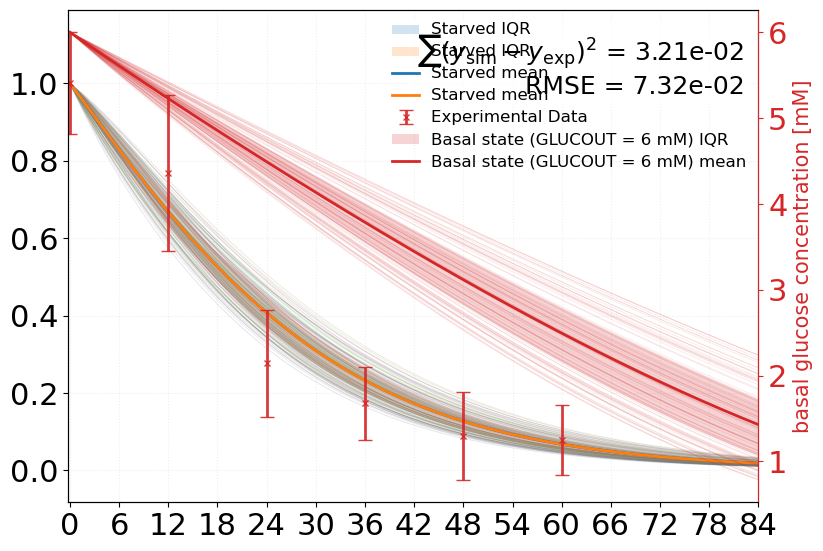

In [294]:
alma = copy.deepcopy(mechs['starve'].orig_time_sim_df)
for xml_name, temp_df in alma.items():
    alma[xml_name]['GLUCOUT'] *= 1e+6

font_sizes={
    "title": 20,
    "suptitle": 22,
    "axis_label": 15,
    "ticks": 22,
    "legend": 12,
    "legend_title": 13,
    "annotation": 18,
    "colorbar_label": 13,
    "colorbar_ticks": 11,
}

fig = plot_compare_summary_gluc(
    df_dict_a=alma,
    df_dict_b=alma,
    label_a='Starved', label_b='Starved',
    species=('GLUCOUT'),
    show_iqr=True, show_p80=False,
    show_mean=True, show_median=False,
    sample_trajs=100, legend_pos="best",
    curve_labels=False,
    #y_label=r"concentration $[mM]$",#[\frac{mol}{dm^{3}}]$",
    figsize=(8, 6),
    font_sizes=font_sizes,
    title="",
    x_label="",
    y_label="",
    add_stac=True,
    stac_df_dict=mechs['stac'].orig_time_sim_df,
    stac_scaling_factor=1e6,
    stac_label='Basal state (GLUCOUT = 6 mM)',
    stac_y_label='basal glucose concentration [mM]',
    stac_color='tab:red',
)

plt.show()

[GLUCOUT] SSE = 3.2140e-02, RMSE = 7.3189e-02


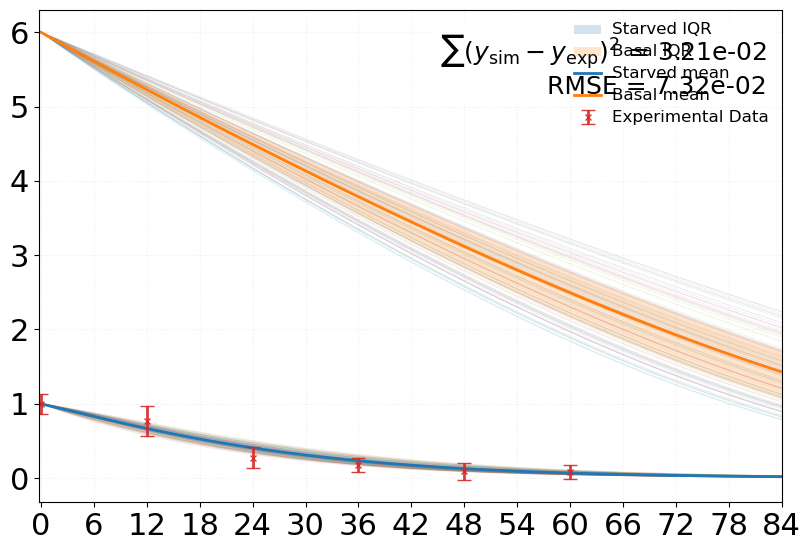

In [295]:
stac_glucose = copy.deepcopy(mechs['stac'].orig_time_sim_df)
for xml_name, temp_df in stac_glucose.items():
    stac_glucose[xml_name]['GLUCOUT'] *= 1e6

fig = plot_compare_summary_gluc(
    df_dict_a=alma,
    df_dict_b=stac_glucose,
    label_a='Starved',
    label_b='Basal',
    species='GLUCOUT',
    show_iqr=True,
    show_p80=False,
    show_mean=True,
    show_median=False,
    sample_trajs=100,
    legend_pos='best',
    curve_labels=False,
    figsize=(8, 6),
    font_sizes=font_sizes,
    title='',
    x_label='',
    y_label='',
    add_stac=False,
)

plt.show()

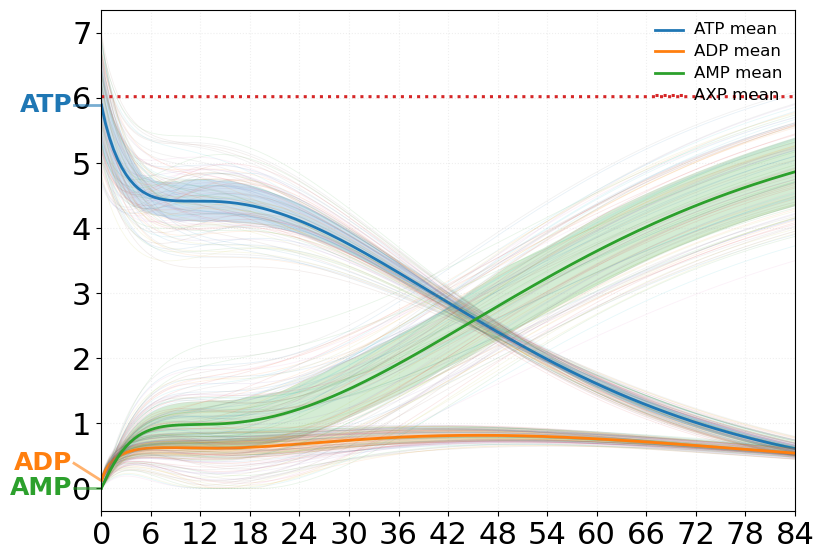

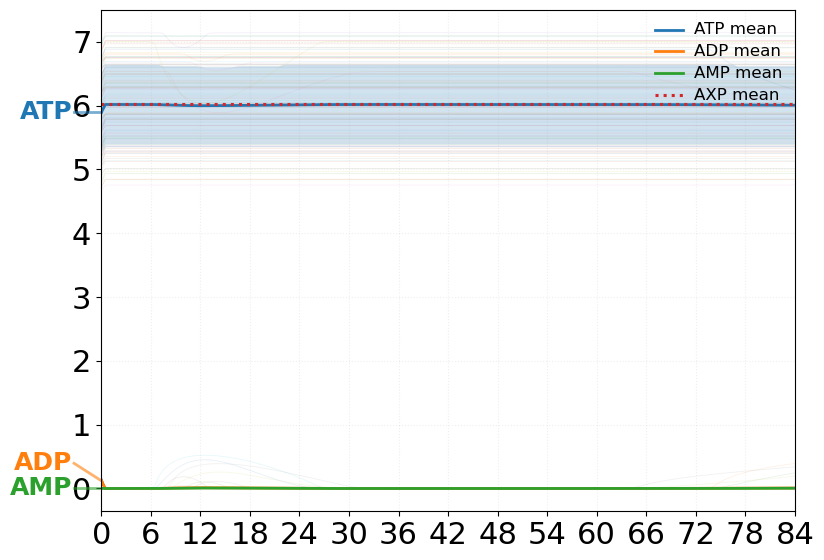

In [296]:
fig = plot_compare_summary_atp(
    df_dict_a=mechs['starve'].orig_time_sim_df,
    df_dict_b=mechs['stac'].orig_time_sim_df,
    label_a='Starved', label_b='Basal',
    species=('ATP', 'ADP', 'AMP'),
    layout_mode="condition",
    show_iqr=True, show_p80=False,
    show_mean=True, show_median=False,
    sample_trajs=100,
    legend_pos="none",
    curve_labels=True,
    curve_label_min_gap_frac=0.05,
    curve_label_xpad=-3.5,
    curve_label_connectors=True,
    figsize=(8, 6),
    separate_conditions=True,
    title="",#'AXP Dynamics',
    font_sizes=font_sizes,
    x_label="",
    y_label="",#r"concentration [$\mu$M]",
    scaling_factor=1e6
    )

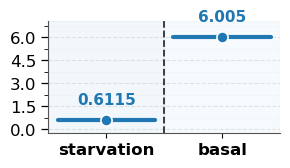

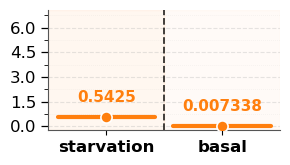

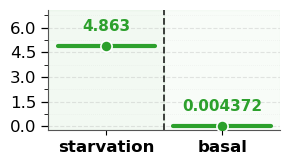

In [304]:
concept_font_sizes = {
    **font_sizes,
    'title': 18,
    'axis_label': 13,
    'ticks': 12,
    'annotation': 11,
    'legend': 11,
}
axp_concept_species = ('ATP', 'ADP', 'AMP')  # Select species here.
axp_concept_figures = plot_endpoint_concept_diagrams(
    df_dict_starvation=mechs['starve'].orig_time_sim_df,
    df_dict_basal=mechs['stac'].orig_time_sim_df,
    species=axp_concept_species,
    scaling_factor=1e6,
    color_species_order=('ATP', 'ADP', 'AMP'),
    #y_label='final concentration [mM]',
    legend_loc='none',
    font_sizes=concept_font_sizes,
    x_label="",
    y_label="",
    title="",
    figsize=(3,1.75),
    y_major_ticks=6,
    shared_y_limits=True,
    y_bottom=-0.25
)

plt.show()

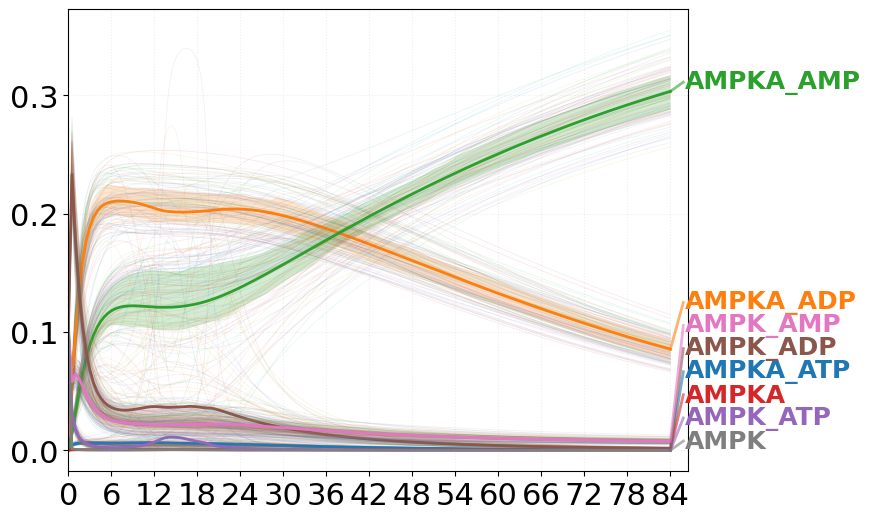

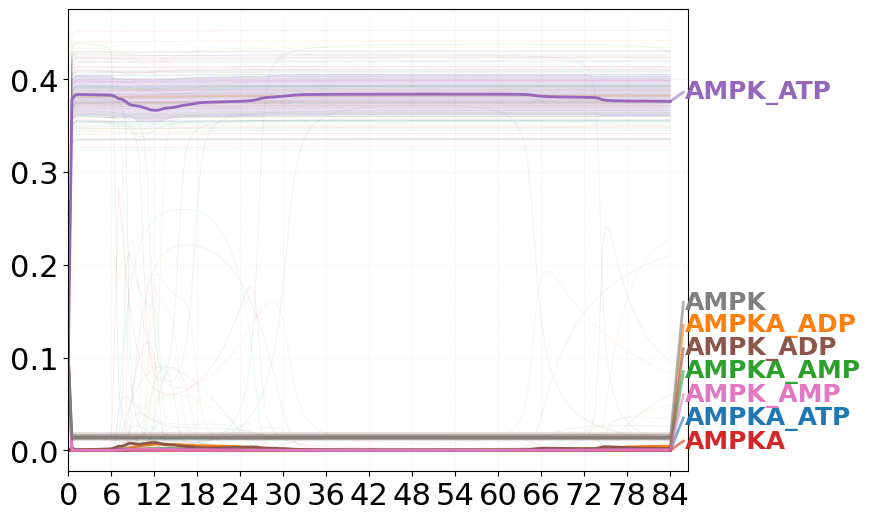

In [165]:
fig = plot_compare_summary_ampk(
    df_dict_a=mechs['starve'].orig_time_sim_df,
    df_dict_b=mechs['stac'].orig_time_sim_df,
    label_a='Starved', label_b='Basal',
    species=('AMPKA_ATP', 'AMPKA_ADP', 'AMPKA_AMP','AMPKA',
             'AMPK_ATP', 'AMPK_ADP', 'AMPK_AMP','AMPK'),
    layout_mode="condition",
    show_iqr=True, show_p80=False,
    show_mean=True, show_median=False,
    sample_trajs=100,
    legend_pos='none',
    curve_labels=True,
    curve_label_min_gap_frac=0.05,
    curve_label_xpad=2.0,
    curve_label_connectors=True,
    figsize=(8, 6),
    separate_conditions=True,
    scaling_factor=1e9,
    title="",#'AXP Dynamics',
    font_sizes=font_sizes,
    x_label="",
    y_label=r"concentration [$\mu$M]",
    )

In [ ]:
ampk_concept_species = ('AMPKA', 'AMPK')  # Select species here.
ampk_concept_figures = plot_endpoint_concept_diagrams(
    df_dict_starvation=mechs['starve'].orig_time_sim_df,
    df_dict_basal=mechs['stac'].orig_time_sim_df,
    species=ampk_concept_species,
    scaling_factor=1e9,
    color_species_order=(
        'AMPKA_ATP', 'AMPKA_ADP', 'AMPKA_AMP', 'AMPKA',
        'AMPK_ATP', 'AMPK_ADP', 'AMPK_AMP', 'AMPK',
    ),
    y_label=r'final concentration [$\mu$M]',
    legend_loc='none',
    font_sizes=concept_font_sizes,
    shared_y_limits=True,
)

plt.show()

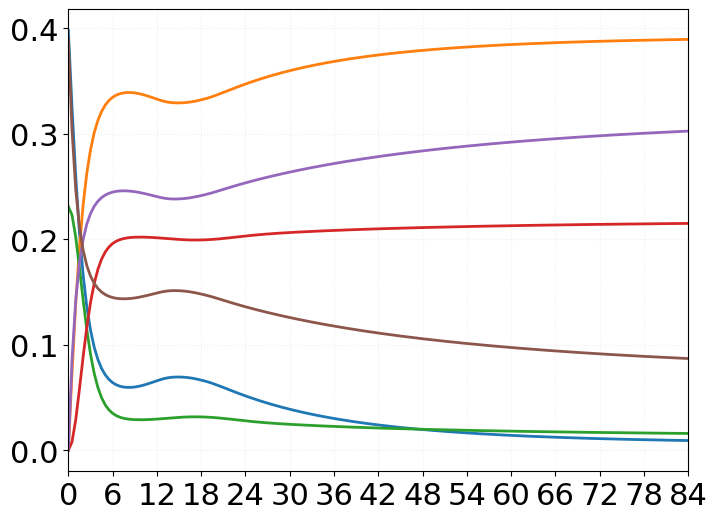

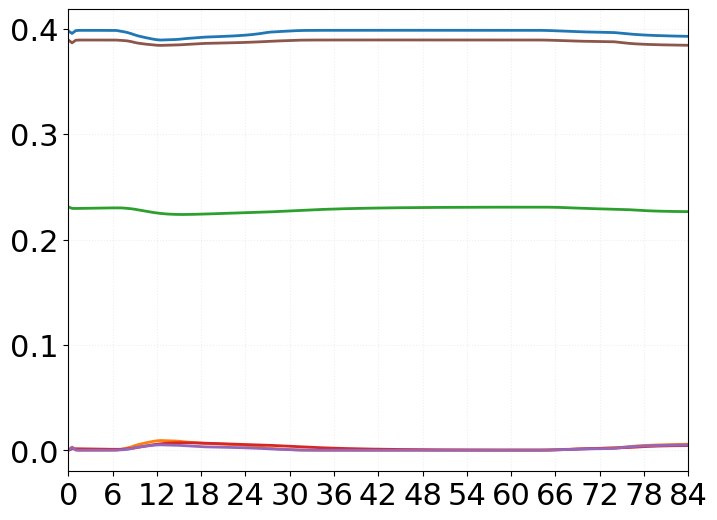

In [166]:
def add_ampk_totals(df_dict,
                    ampk_name='AMPK_t',
                    ampka_name='AMPKA_t'):
    """
    Return a new dict of DataFrames where each df has two extra columns:
    AMPK_tot  = AMPK  + AMPK_ATP  + AMPK_ADP  + AMPK_AMP
    AMPKA_tot = AMPKA + AMPKA_ATP + AMPKA_ADP + AMPKA_AMP
    """
    out = {}
    for key, df in df_dict.items():
        tmp = df.copy()

        tmp[ampk_name] = (
            tmp['AMPK'] +
            tmp['AMPK_ATP'] +
            tmp['AMPK_ADP'] +
            tmp['AMPK_AMP']
        )

        tmp[ampka_name] = (
            tmp['AMPKA'] +
            tmp['AMPKA_ATP'] +
            tmp['AMPKA_ADP'] +
            tmp['AMPKA_AMP']
        )

        out[key] = tmp
    return out

stac_ampk   = add_ampk_totals(mechs['stac'].orig_time_sim_df)
starve_ampk = add_ampk_totals(mechs['starve'].orig_time_sim_df)

fig = plot_compare_summary_ampk(
    df_dict_a=starve_ampk,
    df_dict_b=stac_ampk,
    label_a='Starved',
    label_b='Basal',
    species=('AMPK_t', 'AMPKA_t', 'ULK', 'ULKA', 'MTOR', 'MTORA'),
    layout_mode="condition",   # or "species", as you like
    show_iqr=False, show_p80=False,
    show_mean=True, show_median=False,
    sample_trajs=0,
    legend_pos="none",
    separate_conditions=True, 
    scaling_factor=1e9,
    curve_labels=False,
    curve_label_xfrac=20,        # 1.0 = end of time window
    curve_label_xpad=1.5,         # 1.5 h to the right of that point
    curve_label_y_offset_frac=0.02,  # 2% of y-range above the curve
    figsize=(8, 6),
    title="",#'AXP Dynamics',
    font_sizes=font_sizes,
    x_label="",
    y_label=r"concentration [$\mu$M]",
)

plt.show()

In [ ]:
mtor_ulk_ampk_concept_species = (
    'AMPK_t', 'AMPKA_t', 'ULK', 'ULKA', 'MTOR', 'MTORA',
)  # Select species here.
mtor_ulk_ampk_concept_figures = plot_endpoint_concept_diagrams(
    df_dict_starvation=starve_ampk,
    df_dict_basal=stac_ampk,
    species=mtor_ulk_ampk_concept_species,
    scaling_factor=1e9,
    color_species_order=('AMPK_t', 'AMPKA_t', 'ULK', 'ULKA', 'MTOR', 'MTORA'),
    y_label=r'final concentration [$\mu$M]',
    legend_loc='none',
    font_sizes=concept_font_sizes,
    shared_y_limits=True,
)

plt.show()